# Лабораторна робота № 6
## Конвеєр інтелектуального аналізу даних та інтерпретація моделі

**Інтелектуальний аналіз та візуалізація даних** · 4 години · 4 бали

---

### Постановка

Ви — аналітик інтернет-провайдера. Маркетинг просить модель, яка **в момент
звернення клієнта** оцінює ризик, що той розірве договір протягом кварталу.
Модель потрібна не заради числа: за її підказкою відділ утримання
телефонуватиме людям і пропонуватиме знижку. Тому від вас хочуть **дві речі**:

1. чесну оцінку якості;
2. **пояснення**, чому модель вважає конкретного клієнта ризиковим.

Вам видали вивантаження з CRM. Воно зроблене не для аналізу, а для звітності,
тому в ньому є все підряд — зокрема й те, чого в момент прогнозу ще не існує.

> **Попередження, яке варто прочитати двічі.** Перший результат, який ви
> отримаєте, буде прекрасним. Робота полягає в тому, щоб з'ясувати, чому
> йому не можна вірити, і скільки залишиться після того, як ви приберете
> все зайве.

### Що здаєте

Цей ноутбук із заповненими комірками, виконаними **згори вниз без помилок**,
і відповідями на питання розділу 16.

### Як оцінюється

| Частина | Що оцінюється | Балів |
|---|---|---|
| 1 | Конвеєр: обробка, витік, чесне число, вибір методу | 2,0 |
| 2 | Інтерпретація: важливість, PDP, SHAP | 1,5 |
| 3 | Звіт: обґрунтування рішень і виявлені хибні інтерпретації | 0,5 |

Штраф −0,5 бала, якщо ноутбук не виконується згори вниз на чистому ядрі.

---
## 0. Ваш варіант

Впишіть прізвище та номер у списку групи. Файл даних підтягнеться сам.

In [1]:
STUDENT_NAME = 'Мартин Максим Ігорович'     # напр. 'Коваленко Іван Петрович'
LIST_NUMBER  = 14      # номер у списку групи

assert STUDENT_NAME and LIST_NUMBER > 0, 'впишіть прізвище та номер у списку'
VARIANT = (LIST_NUMBER - 1) % 30 + 1
DATA = 'lr6_варіант_%02d.csv' % VARIANT
print('варіант %d, файл %s' % (VARIANT, DATA))

варіант 14, файл lr6_варіант_14.csv


> Файли варіантів лежать у теці `дані/` поряд із ноутбуком. Якщо викладач
> призначив вам інший варіант — перепишіть `VARIANT` вручну і зазначте це у звіті.

In [2]:
import importlib.util, subprocess, sys
REQUIRED = ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap']
MODNAME  = {'scikit-learn': 'sklearn'}
missing = [p for p in REQUIRED if importlib.util.find_spec(MODNAME.get(p, p)) is None]
if missing:
    print('встановлюю:', ', '.join(missing), '...')
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('усі пакети на місці')

усі пакети на місці


In [3]:
import warnings; warnings.filterwarnings('ignore')
import os, re, json, time, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.model_selection import (RepeatedStratifiedKFold, cross_val_score,
                                     train_test_split)
from sklearn.inspection import permutation_importance, partial_dependence
from sklearn.metrics import roc_auc_score, confusion_matrix, classification_report
from sklearn.tree import DecisionTreeClassifier    # додано: модель «одне дерево» (розділ 7)
from scipy import stats                            # додано: t-квантиль для парного порівняння (7.2)

SEED = 42
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 60)
print('усе імпортовано')

усе імпортовано


In [4]:
# Службова клітинка (додана): перевіряємо, що файл даних на місці.
# Локально файл лежить у теці дані/ поряд із ноутбуком. У Google Colab такої теки немає —
# тоді клітинка попросить завантажити файл і сама покладе його в дані/.
DATA_PATH = os.path.join('дані', DATA)
if not os.path.exists(DATA_PATH):
    os.makedirs('дані', exist_ok=True)
    if os.path.exists(DATA):                    # файл поклали просто поруч із ноутбуком
        os.replace(DATA, DATA_PATH)
    else:
        try:
            from google.colab import files      # цей модуль є лише в Colab
        except ImportError:
            raise FileNotFoundError('Покладіть %s у теку дані/ поряд із ноутбуком' % DATA)
        print('Завантажте файл', DATA)
        uploaded = files.upload()
        os.replace(next(iter(uploaded)), DATA_PATH)
print('файл даних на місці:', DATA_PATH)

файл даних на місці: дані/lr6_варіант_14.csv


---
## 1. Три рішення, які ухвалюють ДО того, як торкнутись даних

Нагадування з лекції 7: кроки 1–3 алгоритму виконуються перш ніж
ви напишете хоч один рядок обробки. Якщо обрати метрику після того, як
побачив результати, ви оберете ту, яка показала більше.

### Завдання 1.1

Заповніть три змінні нижче і **обґрунтуйте кожну** одним реченням у коментарі.

In [5]:
# ----- ВАШІ ВІДПОВІДІ -----

TYPE_OF_TASK = 'класифікація'      # 'класифікація' / 'регресія' / 'кластеризація' / 'зменшення розмірності'
# чому: ціль має лише два значення (1 — розірвав договір, 0 — лишився), а відділу утримання
#       для кожного клієнта потрібна оцінка ризику, тобто ймовірність класу 1.

METRIC = 'AUC'            # 'точність' / 'AUC' / 'F1' / 'повнота' / 'MAE'
# чому саме ця, а не точність: відтік — лише 15–30 % клієнтів, тому модель «ніхто не піде»
#       уже має точність 70–85 % і нульову користь. AUC не залежить від порога і міряє саме те,
#       що потрібно для списку на обдзвін: чи ставить модель тих, хто піде, вище за тих, хто лишиться.

CV_SCHEME = 'стратифікована 5-кратна, 4 повтори'         # напр. 'стратифікована 5-кратна, 4 повтори'
# чому саме така: 1200 рядків — замало, щоб вірити одному поділу; стратифікація тримає однакову
#       частку відтоку в кожній згортці, а 5 × 4 = 20 навчань дають середнє і розкид, а не одне випадкове число.

for nme, val in [('TYPE_OF_TASK', TYPE_OF_TASK), ('METRIC', METRIC), ('CV_SCHEME', CV_SCHEME)]:
    assert val, 'не заповнено: ' + nme
print('рішення зафіксовані')

рішення зафіксовані


> **Підказка до METRIC.** Подивіться на частку відтоку в наступному розділі.
> Якщо вона далека від 50 %, подумайте, яку точність дасть модель
> «ніхто не піде» — і чи варта вона чогось.

---
## 2. Перший погляд на дані

### Завдання 2.1

Прочитайте файл і дайте відповідь на чотири питання: скільки рядків і стовпців,
яка частка відтоку, скільки стовпців має невизначений тип, де найбільше пропусків.

In [6]:
raw = pd.read_csv(os.path.join('дані', DATA), encoding='utf-8-sig')
TARGET = 'відтік'

print('розмір:', raw.shape)
print('частка відтоку: %.3f' % raw[TARGET].mean())
print()
print('типи стовпців:', raw.dtypes.astype(str).value_counts().to_dict())

розмір: (1200, 26)
частка відтоку: 0.258

типи стовпців: {'str': 14, 'float64': 7, 'int64': 5}


In [7]:
# ----- ВАШ КОД: таблиця «стовпець | тип | унікальних | % пропусків | приклад» -----
# Відсортуйте за часткою пропусків спадно і покажіть усі стовпці.
overview = pd.DataFrame({
    'тип': raw.dtypes.astype(str),
    'унікальних': raw.nunique(),
    '% пропусків': (raw.isna().mean() * 100).round(1),
    'приклад': [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
}).sort_values('% пропусків', ascending=False, kind='stable')
overview.index.name = 'стовпець'
display(overview)

# відповіді на чотири питання завдання 2.1
TEXT_COLUMNS = [c for c in raw.columns if not pd.api.types.is_numeric_dtype(raw[c])]
BASELINE_ACC = 1 - raw[TARGET].mean()       # точність моделі «ніхто не піде»
print('рядків × стовпців: %d × %d' % raw.shape)
print('частка відтоку: %.3f  ->  модель «ніхто не піде» мала б точність %.3f' % (raw[TARGET].mean(), BASELINE_ACC))
print('стовпців текстового (невизначеного) типу: %d' % len(TEXT_COLUMNS))
print('   з них мали б бути числами: щомісячний_платіж, трафік_ГБ; датами: дата_підключення, дата_розірвання')
print('найбільше пропусків: %s і %s (по %.1f %%), далі %s (%.1f %%)'
      % (overview.index[0], overview.index[1], overview['% пропусків'].iloc[0],
         overview.index[2], overview['% пропусків'].iloc[2]))

,тип,унікальних,% пропусків,приклад
стовпець,,,,
код_причини_закриття,str,5,74.2,ПЕР-04
дата_розірвання,str,273,74.2,2024-12-14
середній_час_відповіді_хв,float64,265,32.3,12.2
трафік_ГБ,str,958,5.0,91.8
щомісячний_платіж,str,1125,4.0,261.71
аварій_на_ділянці_за_квартал,float64,6,3.0,3.0
id_клієнта,str,1200,0.0,K140000
вік,float64,61,0.0,33.0
стать,str,6,0.0,ч


рядків × стовпців: 1200 × 26
частка відтоку: 0.258  ->  модель «ніхто не піде» мала б точність 0.742
стовпців текстового (невизначеного) типу: 14
   з них мали б бути числами: щомісячний_платіж, трафік_ГБ; датами: дата_підключення, дата_розірвання
найбільше пропусків: код_причини_закриття і дата_розірвання (по 74.2 %), далі середній_час_відповіді_хв (32.3 %)


### Завдання 2.2 — три способи, якими дані вже зіпсовані

У вивантаженні є щонайменше три проблеми, кожна з яких тихо зламає модель.
Знайдіть їх і **назвіть конкретні стовпці**.

1. Числова колонка, у якій частина значень записана **текстом**.
2. Колонка, у якій Excel перетворив число на **дату**.
3. Колонка, пропуски в якій **не випадкові** — їхня наявність сама щось означає
   (механізм MNAR за класифікацією Рубіна, розділ 7.2 конспекту).

In [8]:
# ----- ВАШ КОД: знайдіть і покажіть по кілька прикладів кожної проблеми -----

# 1) і 2) Текстові колонки, де майже всі значення — числа. Шукаємо «зайве»:
#    числа з одиницями (літери) і дати 1900 року (так Excel показує маленьке число як дату).
for c in TEXT_COLUMNS:
    s = raw[c].dropna().astype(str)
    starts_with_number = s.str.match(r'^\s*-?\d')
    with_letters = s[starts_with_number & s.str.contains(r'[A-Za-zА-Яа-яІіЇїЄєҐґ]')]
    excel_dates = s[s.str.match(r'^1900-\d\d-\d\d')]
    if starts_with_number.mean() > 0.8 and (len(with_letters) or len(excel_dates)):
        print('%-18s: текст із літерами — %d, «дати» 1900 року — %d' % (c, len(with_letters), len(excel_dates)))
        print('%18s  приклади: %s' % ('', list(with_letters.head(3)) + list(excel_dates.head(3))))

# 3) Пропуски, які щось означають: для кожної колонки з пропусками дивимось, з чим вони збігаються.
rows = []
for c in raw.columns[raw.isna().any()]:
    na = raw[c].isna()
    rows.append({'стовпець': c, 'пропусків': int(na.sum()),
                 'відтік, де пропуск': round(raw.loc[na, TARGET].mean(), 3),
                 'відтік, де заповнено': round(raw.loc[~na, TARGET].mean(), 3),
                 'серед пропусків «звернень = 0»': round((raw.loc[na, 'кількість_звернень_у_підтримку'] == 0).mean(), 3)})
display(pd.DataFrame(rows).set_index('стовпець'))
# дата_розірвання і код_причини_закриття теж мають «невипадкові» пропуски — це витік, його розберемо в розділі 5.
print('Перехресна таблиця: пропуск у середній_час_відповіді_хв × кількість звернень')
display(pd.crosstab(raw['кількість_звернень_у_підтримку'],
                    raw['середній_час_відповіді_хв'].isna().map({True: 'час пропущено', False: 'час є'})))

щомісячний_платіж : текст із літерами — 27, «дати» 1900 року — 0
                    приклади: ['327.41 грн', '381.89 грн', '590.24 грн']
трафік_ГБ         : текст із літерами — 0, «дати» 1900 року — 3
                    приклади: ['1900-01-07 00:00:00', '1900-01-05 00:00:00', '1900-01-03 00:00:00']


,пропусків,"відтік, де пропуск","відтік, де заповнено",серед пропусків «звернень = 0»
стовпець,,,,
щомісячний_платіж,48,0.208,0.260,0.333
трафік_ГБ,60,0.200,0.261,0.383
аварій_на_ділянці_за_квартал,36,0.333,0.256,0.361
середній_час_відповіді_хв,388,0.232,0.271,1.000
код_причини_закриття,890,0.000,1.000,0.335
дата_розірвання,890,0.000,1.000,0.335


Перехресна таблиця: пропуск у середній_час_відповіді_хв × кількість звернень


середній_час_відповіді_хв,час пропущено,час є
кількість_звернень_у_підтримку,,
0,388,0
1,0,426
2,0,261
3,0,91
4,0,29
5,0,4
6,0,1


In [9]:
PROBLEM_TEXT_IN_NUMBER = 'щомісячний_платіж'           # частину сум записано з одиницями: '327.41 грн'
PROBLEM_EXCEL_DATE     = 'трафік_ГБ'                   # Excel перетворив малі числа на дати: '1900-01-07 00:00:00'
PROBLEM_MNAR           = 'середній_час_відповіді_хв'   # 388 пропусків (32 %), і всі — у тих, хто не звертався
MNAR_MEANING           = ('пропуск означає, що клієнт жодного разу не звертався в підтримку '
                          '(в усіх пропусках кількість звернень = 0), тож часу відповіді для нього просто не існує: '
                          'це не «забули записати», а «нема чого записувати»')

for nme, val in [('PROBLEM_TEXT_IN_NUMBER', PROBLEM_TEXT_IN_NUMBER),
                 ('PROBLEM_EXCEL_DATE', PROBLEM_EXCEL_DATE),
                 ('PROBLEM_MNAR', PROBLEM_MNAR), ('MNAR_MEANING', MNAR_MEANING)]:
    assert val, 'не заповнено: ' + nme
assert PROBLEM_TEXT_IN_NUMBER in raw.columns and PROBLEM_EXCEL_DATE in raw.columns
assert PROBLEM_MNAR in raw.columns
print('проблеми названо')

проблеми названо


---
## 3. Будуємо матрицю ознак

Перетворення сирої таблиці на матрицю `X` — це фаза 3 CRISP-DM. Усі рішення
тут приймаються **явно** і записуються, бо потім їх доведеться захищати.

### Завдання 3.1

Допишіть `to_number` і `build_X`.

* `to_number` має витягати число з тексту `'350.5 грн'`, **не** перетворювати
  дату на число і повертати `NaN` там, де числа немає.
* `build_X` для кожного стовпця вирішує: число, категорія чи викинути.
  Дата підключення має стати **числом** (напр. порядковим номером дня) —
  інакше модель її не з'їсть.

In [10]:
DATE_RE = re.compile(r'^\s*(\d{4}-\d{1,2}-\d{1,2}|\d{1,2}[./]\d{1,2}[./]\d{2,4})')  # 2024-03-26, 1900-01-11 00:00:00, 11.01.1900
NUM_RE = re.compile(r'[-+]?\d+(?:[.,]\d+)?')                                      # 350.5, 2,75, -3


def to_number(s):
    """Витягує число з колонки, де перемішані числа, текст і дати."""
    def one(v):
        # 1) None / NaN            -> np.nan
        if v is None or (isinstance(v, float) and np.isnan(v)):
            return np.nan
        # 2) datetime / Timestamp  -> np.nan   (це брак, а не дані)
        if isinstance(v, (datetime.date, np.datetime64)):    # datetime і pd.Timestamp — підвиди date
            return np.nan
        # 3) число                 -> float
        if isinstance(v, (int, float, np.number)):
            return float(v)
        # 4) текст                 -> перше число в ньому, інакше np.nan
        t = str(v).strip()
        if DATE_RE.match(t):        # дата, записана текстом ('1900-01-07 00:00:00'), — теж брак
            return np.nan
        m = NUM_RE.search(t)
        return float(m.group().replace(',', '.')) if m else np.nan
    return s.map(one).astype(float)


# самоперевірка
_t = pd.Series([1, '350.5 грн', '2,75', datetime.datetime(1900, 1, 11), None, 'немає'])
_r = to_number(_t)
assert _r[0] == 1.0 and abs(_r[1] - 350.5) < 1e-9 and abs(_r[2] - 2.75) < 1e-9
assert np.isnan(_r[3]), 'дата має стати NaN, а не числом'
assert np.isnan(_r[4]) and np.isnan(_r[5])
print('to_number працює')

to_number працює


In [11]:
DROP_ALWAYS = ['id_клієнта']   # ідентифікатор: нічого не пояснює, лише запам'ятовується
SEX_MAP = {'чол': 'ч', 'жін': 'ж'}   # стать записана неохайно: ч / Ч / чол і ж / Ж / жін


def looks_like_number(v):
    """Текст «починається з числа»: '327.41 грн' — так; 'КОД-027' чи дата — ні."""
    t = str(v).strip()
    return bool(re.match(r'^[-+]?\d', t)) and not DATE_RE.match(t)


def build_X(d, drop):
    """Сира таблиця -> матриця ознак. Категорії лишаємо типом category."""
    X = pd.DataFrame(index=d.index)
    log = []
    for c in d.columns:
        if c in drop or c == TARGET:
            continue
        s = d[c]
        filled = s.dropna().astype(str)
        if pd.api.types.is_numeric_dtype(s):
            # числова -> float
            X[c] = s.astype(float)
            how = 'число'
        elif len(filled) and filled.map(lambda v: bool(DATE_RE.match(v))).mean() > 0.8:
            # дата -> число: номер дня, відлічений від 01.01.2000
            X[c] = (pd.to_datetime(s, errors='coerce') - pd.Timestamp('2000-01-01')).dt.days.astype(float)
            how = 'дата -> число (день)'
        elif len(filled) and filled.map(looks_like_number).mean() > 0.8:
            # текстова колонка, де >80% значень розбираються в число -> число
            X[c] = to_number(s)
            how = 'текст -> число'
        else:
            # інша текстова -> category: прибираємо пробіли, зводимо до малих літер
            t = s.map(lambda v: str(v).strip().lower() if pd.notna(v) else np.nan)
            if c == 'стать':
                t = t.replace(SEX_MAP)
            X[c] = t.astype('category')
            how = 'категорія'
        log.append({'стовпець': c, 'рішення': how, 'різних значень': X[c].nunique(),
                    'пропусків': int(X[c].isna().sum())})
    for c in drop:
        if c in d.columns:
            log.append({'стовпець': c, 'рішення': 'викинуто', 'різних значень': d[c].nunique(),
                        'пропусків': int(d[c].isna().sum())})
    return X, pd.DataFrame(log)


X_all, log = build_X(raw, DROP_ALWAYS)
y = raw[TARGET].astype(int)
print('матриця ознак:', X_all.shape)
print('категоріальних:', sum(str(X_all[c].dtype) == 'category' for c in X_all.columns))
display(log)

# перевірка чистки: стать — два рівні; «дати» в трафік_ГБ стали NaN, а не 1900
print('стать після чистки:', X_all['стать'].value_counts().to_dict())
print('трафік_ГБ: пропусків було %d, стало %d (+%d «дати» Excel)'
      % (raw['трафік_ГБ'].isna().sum(), X_all['трафік_ГБ'].isna().sum(),
         X_all['трафік_ГБ'].isna().sum() - raw['трафік_ГБ'].isna().sum()))

матриця ознак: (1200, 24)
категоріальних: 9


,стовпець,рішення,різних значень,пропусків
0,вік,число,61,0
1,стать,категорія,2,0
2,місто,категорія,6,0
3,філія,категорія,6,0
4,тариф,категорія,4,0
5,тип_підключення,категорія,3,0
6,спосіб_оплати,категорія,3,0
7,автоплатіж,категорія,2,0
8,кількість_послуг,число,3,0
9,місяців_обслуговування,число,81,0


стать після чистки: {'ч': 611, 'ж': 589}
трафік_ГБ: пропусків було 60, стало 63 (+3 «дати» Excel)


### Завдання 3.2 — конвеєр

Зберіть `make_pipe(X, clf)`: колонковий перетворювач (числові — медіана плюс
стандартизація; категоріальні — мода плюс одиничне кодування) і модель.

> **Чому саме так.** Відповідь у розділі 10 конспекту: усе, що має `fit`,
> мусить опинитись **усередині** конвеєра, інакше крос-валідація бреше.
> Зверніть увагу на `handle_unknown='ignore'` — без нього модель упаде на
> категорії, якої не було в навчальній згортці.

In [12]:
def make_pipe(X, clf):
    """Конвеєр = обробка + модель в одному об'єкті.
    Усе, що має fit (медіани, середні, словник категорій), рахується ЛИШЕ на навчальній згортці."""
    cat = [c for c in X.columns if str(X[c].dtype) == 'category']
    num = [c for c in X.columns if c not in cat]
    prep = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')),          # пропуск -> медіана
                          ('sc', StandardScaler())]), num),                    # середнє 0, розкид 1
        ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),    # пропуск -> найчастіше значення
                          ('oh', OneHotEncoder(handle_unknown='ignore',        # невідомий рівень не валить модель
                                               sparse_output=False))]), cat),  # один стовпець 0/1 на кожен рівень
    ])
    return Pipeline([('prep', prep), ('clf', clf)])


def logreg():
    return LogisticRegression(max_iter=3000, random_state=SEED)


cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=4, random_state=SEED)

# самоперевірка: конвеєр має бути єдиним оцінювачем і переживати крос-валідацію
_p = make_pipe(X_all, logreg())
assert hasattr(_p, 'fit') and hasattr(_p, 'predict')
_s = cross_val_score(_p, X_all, y, cv=RepeatedStratifiedKFold(
    n_splits=5, n_repeats=1, random_state=SEED), scoring='roc_auc')
assert len(_s) == 5
print('конвеєр зібрано, пробний прогін AUC %.3f' % _s.mean())

конвеєр зібрано, пробний прогін AUC 0.995


---
## 4. Перший результат

Запустіть модель на **всьому, що є**, — саме так робить дев'ять аналітиків
із десяти, коли їм дали вивантаження і попросили «подивитись, чи взагалі
щось передбачається».

In [13]:
t0 = time.time()
auc_naive = cross_val_score(make_pipe(X_all, logreg()), X_all, y, cv=cv, scoring='roc_auc')
print('ознак    : %d' % X_all.shape[1])
print('AUC      : %.3f ± %.3f' % (auc_naive.mean(), auc_naive.std()))
print('час      : %.1f c' % (time.time() - t0))

ознак    : 24
AUC      : 0.994 ± 0.003
час      : 0.5 c


### Завдання 4.1

Подивіться на число і на таблицю орієнтирів AUC з розділу 4.4 конспекту.

Запишіть у `FIRST_REACTION` одне речення: що саме це число означає
і яка з двох причин високої AUC, найімовірніше, спрацювала.

In [14]:
FIRST_REACTION = ('AUC %.3f: модель майже безпомилково ставить тих, хто пішов, вище за тих, хто лишився. '
                  'На реальних даних так не буває (0.95 і вище — майже завжди витік), тож спрацювала не «легка задача», '
                  'а витік: у вивантаженні є стовпці, заповнені вже після розірвання договору.' % auc_naive.mean())
assert FIRST_REACTION, 'напишіть, що ви думаєте про це число'
print(FIRST_REACTION)

AUC 0.994: модель майже безпомилково ставить тих, хто пішов, вище за тих, хто лишився. На реальних даних так не буває (0.95 і вище — майже завжди витік), тож спрацювала не «легка задача», а витік: у вивантаженні є стовпці, заповнені вже після розірвання договору.


---
## 5. Шукаємо витік

Чотири типи витоку (розділ 9.1 конспекту) і засіб проти кожного:

| Тип | Засіб |
|---|---|
| цільовий | чек-ліст: чи існує значення в момент прогнозу |
| препроцесинговий | конвеєр |
| часовий | часова схема перевірки |
| груповий | групова схема перевірки |

Починаємо з цільового.

### Завдання 5.1 — автоматичний детектор

Напишіть `leak_scan`: для кожного стовпця перевірте, чи **сам факт
заповненості** передбачає клас. Поріг `min_group` обов'язковий — без нього
детектор видає хибні спрацювання на колонках, заповнених у двох клієнтів.

In [15]:
def leak_scan(d, y, min_group=20):
    """Для кожного стовпця: наскільки добре його заповненість вгадує клас.

    Повертає таблицю зі стовпцями: ознака, заповнено, частка_відтоку_де_заповнено,
    частка_відтоку_де_пропуск, показник (0.5 = нічого, 1.0 = ідеальний поділ).
    """
    rows = []
    for c in d.columns:
        if c == TARGET:
            continue
        filled = d[c].notna()
        n_filled, n_empty = int(filled.sum()), int((~filled).sum())
        if n_filled > min_group and n_empty > min_group:
            score = roc_auc_score(y, filled.astype(int))
            score = max(score, 1 - score)    # напрям не важливий: «заповнено лише в тих, хто лишився» — теж витік
        else:
            score = np.nan                   # одна з груп замала (або пропусків немає) — судити не можна
        rows.append({'ознака': c, 'заповнено': n_filled,
                     'частка_відтоку_де_заповнено': round(y[filled].mean(), 3) if n_filled else np.nan,
                     'частка_відтоку_де_пропуск': round(y[~filled].mean(), 3) if n_empty else np.nan,
                     'показник': round(score, 3)})
    return pd.DataFrame(rows).sort_values('показник', ascending=False)


scan = leak_scan(raw, y)
display(scan.head(10))

,ознака,заповнено,частка_відтоку_де_заповнено,частка_відтоку_де_пропуск,показник
22,код_причини_закриття,310,1.000,0.000,1.000
23,дата_розірвання,310,1.000,0.000,1.000
17,середній_час_відповіді_хв,812,0.271,0.232,0.522
14,трафік_ГБ,1140,0.261,0.200,0.508
16,аварій_на_ділянці_за_квартал,1164,0.256,0.333,0.506
12,щомісячний_платіж,1152,0.260,0.208,0.505
0,id_клієнта,1200,0.258,NaN,NaN
1,вік,1200,0.258,NaN,NaN
2,стать,1200,0.258,NaN,NaN
3,місто,1200,0.258,NaN,NaN


### Завдання 5.2 — цільовий витік

Стовпці з показником близько 1,0 заповнені **лише в одного класу**. Такий
стовпець записаний уже після того, як результат став відомий.

Випишіть їх у `TARGET_LEAK` і **для кожного поясніть одним реченням**, чому
його не існує в момент прогнозу.

In [16]:
TARGET_LEAK = [
    'дата_розірвання',        # з'являється лише в день розірвання, тобто ПІСЛЯ того, що ми прогнозуємо
    'код_причини_закриття',   # причину записують, коли договір уже закривають
]
assert len(TARGET_LEAK) >= 2, 'таких стовпців більше ніж один'
assert all(c in raw.columns for c in TARGET_LEAK)
print('цільовий витік:', TARGET_LEAK)

цільовий витік: ['дата_розірвання', 'код_причини_закриття']


In [17]:
X2, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK)
auc2 = cross_val_score(make_pipe(X2, logreg()), X2, y, cv=cv, scoring='roc_auc')
print('після вилучення цільового витоку: %d ознак, AUC %.3f ± %.3f'
      % (X2.shape[1], auc2.mean(), auc2.std()))

після вилучення цільового витоку: 22 ознак, AUC 0.977 ± 0.006


### Завдання 5.3 — витік, якого детектор НЕ бачить

Число майже не впало. Отже головне ще попереду.

Детектор знаходить колонки, **формально** пов'язані з ціллю. Він безсилий
проти колонки, яка формально бездоганна, але якої **не існує в момент,
коли ухвалюється рішення** — або яка означає не те, що здається.

Перегляньте решту стовпців **очима** і поставте кожному питання з розділу 9.3:

> **Чи міг я знати це значення в ту мить, коли треба ухвалити рішення?**

Нагадування про момент прогнозу: клієнт щойно зателефонував, договір
**чинний**, рішення про знижку ухвалюється **зараз**.

In [18]:
# ----- ВАШ КОД: перегляньте список стовпців, що лишились -----
print(list(X2.columns))

# Чек-ліст для «підозрілих» полів (розділ 2.2 методички): коли поле з'являється в житті клієнта
# і чи існує воно в момент прогнозу (клієнт щойно подзвонив, договір чинний, рішення — зараз).
checklist = pd.DataFrame([
    ('дата_розірвання', 'у день розірвання договору', 'ні — цільовий витік'),
    ('код_причини_закриття', 'під час закриття договору', 'ні — цільовий витік'),
    ('оцінка_ризику_менеджером', 'менеджер ставить, уже побачивши поведінку клієнта', 'ні — оцінка людини'),
    ('трафік_МБ', 'щоквартально, разом із трафік_ГБ', 'так (але це той самий трафік ×1024)'),
    ('код_тарифного_плану', 'при підключенні', 'так'),
    ('скоринг_партнера', 'зовнішній бал від партнера', 'так'),
], columns=['стовпець', 'коли з’являється', 'чи є в момент прогнозу']).set_index('стовпець')
display(checklist)

# Доказ щодо оцінки менеджера: вона заповнена в усіх, але майже дорівнює відповіді
mgr = pd.crosstab(raw['оцінка_ризику_менеджером'], y).rename(columns={0: 'лишились', 1: 'пішли'})
mgr['частка відтоку'] = (mgr['пішли'] / mgr.sum(axis=1)).round(3)
display(mgr)
print('пропусків в оцінці менеджера: %d' % raw['оцінка_ризику_менеджером'].isna().sum())
print('AUC самої оцінки менеджера, без жодної моделі: %.3f' % roc_auc_score(y, raw['оцінка_ризику_менеджером']))

['вік', 'стать', 'місто', 'філія', 'тариф', 'тип_підключення', 'спосіб_оплати', 'автоплатіж', 'кількість_послуг', 'місяців_обслуговування', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж', 'знижка_відсоток', 'трафік_ГБ', 'кількість_звернень_у_підтримку', 'аварій_на_ділянці_за_квартал', 'середній_час_відповіді_хв', 'трафік_МБ', 'код_тарифного_плану', 'скоринг_партнера', 'дата_підключення', 'оцінка_ризику_менеджером']


,коли з’являється,чи є в момент прогнозу
стовпець,,
дата_розірвання,у день розірвання договору,ні — цільовий витік
код_причини_закриття,під час закриття договору,ні — цільовий витік
оцінка_ризику_менеджером,"менеджер ставить, уже побачивши поведінку клієнта",ні — оцінка людини
трафік_МБ,"щоквартально, разом із трафік_ГБ",так (але це той самий трафік ×1024)
код_тарифного_плану,при підключенні,так
скоринг_партнера,зовнішній бал від партнера,так


відтік,лишились,пішли,частка відтоку
оцінка_ризику_менеджером,,,
1.0,235,1,0.004
2.0,409,8,0.019
3.0,213,62,0.225
4.0,32,130,0.802
5.0,1,109,0.991


пропусків в оцінці менеджера: 0
AUC самої оцінки менеджера, без жодної моделі: 0.945


In [19]:
HUMAN_LEAK = [
    'оцінка_ризику_менеджером',   # ставить менеджер, який уже бачив поведінку клієнта (скарги, дзвінки, намір піти)
]
HUMAN_LEAK_WHY = ('детектор перевіряє лише, чи сам ФАКТ заповненості вгадує клас; оцінка менеджера заповнена '
                  'в усіх %d клієнтів, тож за заповненістю вона нічого не розрізняє. Але її ставить людина, яка вже '
                  'бачила поведінку клієнта, тому за змістом вона майже дорівнює відповіді: з оцінкою 5 пішли %d із %d, '
                  'з оцінкою 1 — %d із %d'
                  % (raw['оцінка_ризику_менеджером'].notna().sum(),
                     mgr.loc[5, 'пішли'], mgr.loc[5].iloc[:2].sum(), mgr.loc[1, 'пішли'], mgr.loc[1].iloc[:2].sum()))

assert len(HUMAN_LEAK) >= 1 and HUMAN_LEAK_WHY
assert all(c in raw.columns for c in HUMAN_LEAK)
X3, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK)
auc3 = cross_val_score(make_pipe(X3, logreg()), X3, y, cv=cv, scoring='roc_auc')
print('після вилучення оцінок людини: %d ознак, AUC %.3f ± %.3f'
      % (X3.shape[1], auc3.mean(), auc3.std()))
print()
print(HUMAN_LEAK_WHY)

після вилучення оцінок людини: 21 ознак, AUC 0.863 ± 0.023

детектор перевіряє лише, чи сам ФАКТ заповненості вгадує клас; оцінка менеджера заповнена в усіх 1200 клієнтів, тож за заповненістю вона нічого не розрізняє. Але її ставить людина, яка вже бачила поведінку клієнта, тому за змістом вона майже дорівнює відповіді: з оцінкою 5 пішли 109 із 110, з оцінкою 1 — 1 із 236


> Якщо тут число впало **суттєво** — ви знайшли головне. Якщо ні —
> перечитайте список стовпців ще раз: щось лишилось.

---
## 6. Артефакт збору даних

Лишилась найтонша перевірка. Якщо дані про два класи **збиралися
по-різному** — у різні періоди, різними людьми, за різними правилами —
модель вивчає спосіб запису, а не предмет. Жодна окрема колонка при цьому
не є витоком; витоком є вся таблиця.

Обчислювана перевірка з розділу 9.3: спробувати передбачити **не ціль,
а джерело**. Якщо за тими самими чесними ознаками добре вгадується філія
або період підключення — класи не порівнянні між собою.

### Завдання 6.1 — частка відтоку за філіями і за періодом

,частка_відтоку,клієнтів
філія,,
Ф-01 Центр,0.465,198
Ф-02 Захід,0.382,170
Ф-03 Схід,0.169,231
Ф-04 Південь,0.181,182
Ф-05 Північ,0.206,209
Ф-06 Приміська,0.181,210


квартал підключення,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4
частка_відтоку,0.205,0.301,0.278,0.275,0.271,0.243,0.25,0.244
клієнтів,156.000,153.000,158.000,153.000,140.000,140.000,144.00,156.000


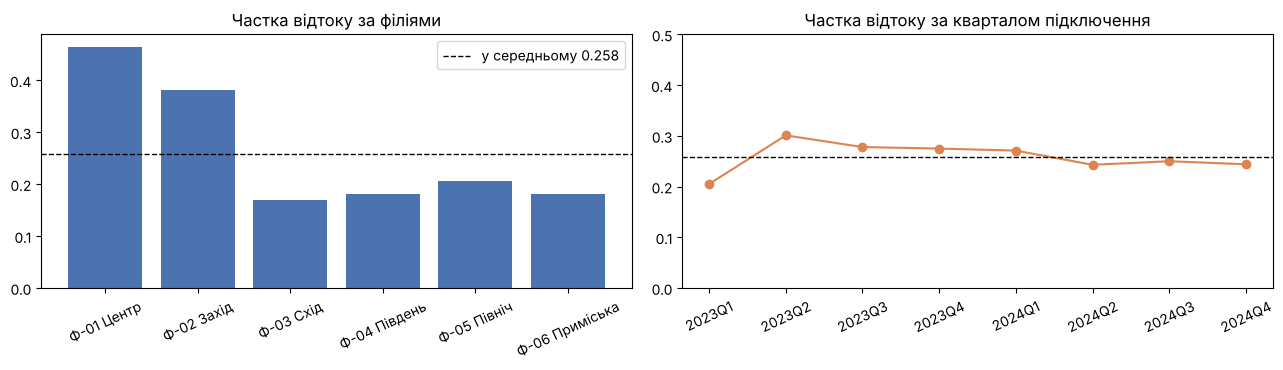

Сходинка є між філіями: дві філії мають відтік 0.382–0.465, решта чотири — 0.169–0.206.
За кварталами підключення сходинки немає: від 0.205 до 0.301 без різкого зламу.


In [20]:
# ----- ВАШ КОД -----
# 1) частка відтоку за кожною філією (і скільки клієнтів у кожній);
by_branch = raw.groupby('філія')[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
display(by_branch)

# 2) частка відтоку по кварталах дати підключення — таблицею або графіком.
quarter = pd.to_datetime(raw['дата_підключення']).dt.to_period('Q').astype(str)
by_quarter = raw.groupby(quarter)[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
by_quarter.index.name = 'квартал підключення'
display(by_quarter.T)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].bar(by_branch.index, by_branch['частка_відтоку'], color='#4C72B0')
ax[0].axhline(y.mean(), color='k', ls='--', lw=1, label='у середньому %.3f' % y.mean())
ax[0].set_title('Частка відтоку за філіями'); ax[0].tick_params(axis='x', rotation=25); ax[0].legend()
ax[1].plot(by_quarter.index, by_quarter['частка_відтоку'], 'o-', color='#DD8452')
ax[1].axhline(y.mean(), color='k', ls='--', lw=1)
ax[1].set_ylim(0, 0.5); ax[1].set_title('Частка відтоку за кварталом підключення'); ax[1].tick_params(axis='x', rotation=25)
plt.tight_layout(); plt.show()
# Шукайте СХОДИНКУ, а не плавну зміну.
print('Сходинка є між філіями: дві філії мають відтік %.3f–%.3f, решта чотири — %.3f–%.3f.'
      % (by_branch['частка_відтоку'].nlargest(2).min(), by_branch['частка_відтоку'].max(),
         by_branch['частка_відтоку'].nsmallest(4).min(), by_branch['частка_відтоку'].nsmallest(4).max()))
print('За кварталами підключення сходинки немає: від %.3f до %.3f без різкого зламу.'
      % (by_quarter['частка_відтоку'].min(), by_quarter['частка_відтоку'].max()))

### Завдання 6.2 — передбачити джерело

Візьміть **ті самі чесні ознаки**, що й для моделі відтоку, і спробуйте
передбачити ними не `відтік`, а ознаку джерела: «клієнт із філії-підозрюваної»
або «підключений після дати-зламу».

Якщо AUC помітно вища за 0,5 — у ваших даних закодоване джерело.

In [21]:
SUSPECT = 'філія'        # 'філія' або 'дата_підключення' — що саме ви підозрюєте
assert SUSPECT in ('філія', 'дата_підключення')

# ----- ВАШ КОД: побудуйте бінарну змінну source -----
# для 'філія': 1 для філій із різко іншою часткою відтоку (сходинка з 6.1: понад 0.30 проти 0.17–0.21)
SUSPECT_BRANCHES = by_branch.index[by_branch['частка_відтоку'] > 0.30].tolist()
source = raw['філія'].isin(SUSPECT_BRANCHES).astype(int)
print('філії-підозрювані:', SUSPECT_BRANCHES, '— клієнтів %d з %d' % (source.sum(), len(source)))

X4, _ = build_X(raw, DROP_ALWAYS + TARGET_LEAK + HUMAN_LEAK + [SUSPECT])
auc_src = cross_val_score(make_pipe(X4, logreg()), X4, source, cv=cv, scoring='roc_auc')
auc4 = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
print('ті самі ознаки передбачають ДЖЕРЕЛО : AUC %.3f' % auc_src.mean())
print('ті самі ознаки передбачають ВІДТІК  : AUC %.3f ± %.3f' % (auc4.mean(), auc4.std()))

# чим клієнти «підозрюваних» філій відрізняються від решти (звідси і вгадування джерела)
diff_src = pd.DataFrame({'Ф-01/Ф-02': X4[source == 1].select_dtypes('number').mean(),
                         'інші філії': X4[source == 0].select_dtypes('number').mean()})
print('частка оптики: %.2f проти %.2f; оплата карткою: %.2f проти %.2f'
      % ((X4.loc[source == 1, 'тип_підключення'] == 'оптика').mean(), (X4.loc[source == 0, 'тип_підключення'] == 'оптика').mean(),
         (X4.loc[source == 1, 'спосіб_оплати'] == 'картка').mean(), (X4.loc[source == 0, 'спосіб_оплати'] == 'картка').mean()))
display(diff_src.loc[['вік', 'швидкість_тарифу_Мбіт', 'місяців_обслуговування']].round(1))

філії-підозрювані: ['Ф-01 Центр', 'Ф-02 Захід'] — клієнтів 368 з 1200
ті самі ознаки передбачають ДЖЕРЕЛО : AUC 0.700
ті самі ознаки передбачають ВІДТІК  : AUC 0.819 ± 0.022
частка оптики: 0.85 проти 0.70; оплата карткою: 0.76 проти 0.63


,Ф-01/Ф-02,інші філії
вік,37.2,40.4
швидкість_тарифу_Мбіт,364.8,280.3
місяців_обслуговування,26.0,23.4


### Завдання 6.3 — драбина

Зведіть усі чотири числа в одну таблицю і подивіться, **де саме** впало.

In [22]:
ladder = pd.DataFrame([
    {'крок': '1. усе підряд',               'ознак': X_all.shape[1], 'AUC': auc_naive.mean()},
    {'крок': '2. мінус цільовий витік',     'ознак': X2.shape[1],    'AUC': auc2.mean()},
    {'крок': '3. мінус оцінки людини',      'ознак': X3.shape[1],    'AUC': auc3.mean()},
    {'крок': '4. мінус артефакт збору',     'ознак': X4.shape[1],    'AUC': auc4.mean()},
]).set_index('крок').round(3)
display(ladder)

HONEST_AUC = float(auc4.mean())
print('чесне число: %.3f ± %.3f' % (HONEST_AUC, auc4.std()))

,ознак,AUC
крок,,
1. усе підряд,24,0.994
2. мінус цільовий витік,22,0.977
3. мінус оцінки людини,21,0.863
4. мінус артефакт збору,20,0.819


чесне число: 0.819 ± 0.022


### Завдання 6.4

Чи **правильно** викидати підозрюваний стовпець? Це не риторичне питання:
філія або дата підключення цілком можуть нести справжній сигнал
(щільна забудова, нові тарифи), а не лише артефакт.

Запишіть своє рішення і аргумент. Обидві відповіді приймаються — оцінюється
аргумент, а не вибір.

In [23]:
DECISION_ARTEFACT = 'викинути'    # 'викинути' / 'залишити' / 'залишити, але звітувати окремо'
DECISION_WHY = ('модель має працювати в будь-якій філії, а зараз вона частково вгадує філію, а не відтік. '
                'Частка відтоку в %s — %.3f–%.3f проти %.3f–%.3f в інших: це сходинка, тобто, найімовірніше, інше правило '
                'обліку розірвань, а не плавна різниця між людьми. Ті самі чесні ознаки вгадують «підозрювану» філію '
                'з AUC %.3f, тож без філії модель не спиратиметься на спосіб запису. Ціна рішення — AUC %.3f -> %.3f; '
                'замовнику варто сказати, що в Ф-01 і Ф-02 модель могла б виглядати точнішою лише через інший облік.'
                % (' і '.join(SUSPECT_BRANCHES), by_branch['частка_відтоку'].nlargest(2).min(), by_branch['частка_відтоку'].max(),
                   by_branch['частка_відтоку'].nsmallest(4).min(), by_branch['частка_відтоку'].nsmallest(4).max(),
                   auc_src.mean(), auc3.mean(), auc4.mean()))
assert DECISION_ARTEFACT and DECISION_WHY
print(DECISION_ARTEFACT, '—', DECISION_WHY)

викинути — модель має працювати в будь-якій філії, а зараз вона частково вгадує філію, а не відтік. Частка відтоку в Ф-01 Центр і Ф-02 Захід — 0.382–0.465 проти 0.169–0.206 в інших: це сходинка, тобто, найімовірніше, інше правило обліку розірвань, а не плавна різниця між людьми. Ті самі чесні ознаки вгадують «підозрювану» філію з AUC 0.700, тож без філії модель не спиратиметься на спосіб запису. Ціна рішення — AUC 0.863 -> 0.819; замовнику варто сказати, що в Ф-01 і Ф-02 модель могла б виглядати точнішою лише через інший облік.


---
## 7. Крок 4 алгоритму: який метод узяти

Тепер, коли набір ознак чесний, можна обирати модель. Критеріїв чотири
(розділ 6 конспекту), і всі чотири вимірюються.

### Завдання 7.1

Порівняйте щонайменше чотири моделі **на тому самому наборі й тій самій
схемі перевірки**. Для кожної запишіть AUC, розкид і час на 100 навчань.

In [24]:
MODELS = {
    'логістична регресія':  logreg(),
    # дерево обмежене (глибина 5, у листку ≥ 20 клієнтів), інакше воно просто запам'ятовує навчальні дані
    'одне дерево':          DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=SEED),
    'випадковий ліс':       RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
    'гістограмний бустинг': HistGradientBoostingClassifier(random_state=SEED),
}

rows = []
for name, clf in MODELS.items():
    assert clf is not None, 'заповніть модель: ' + name
    t0 = time.time()
    a = cross_val_score(make_pipe(X4, clf), X4, y, cv=cv, scoring='roc_auc')
    # cross_val_score робить 5 × 4 = 20 навчань, тому час перераховуємо на 100 навчань
    rows.append({'модель': name, 'AUC': round(a.mean(), 3), '±': round(a.std(), 3),
                 'с на 100 навчань': round((time.time() - t0) * 100 / cv.get_n_splits(), 1)})
cmp_models = pd.DataFrame(rows).set_index('модель')
display(cmp_models)

,AUC,±,с на 100 навчань
модель,,,
логістична регресія,0.819,0.022,3.4
одне дерево,0.748,0.037,2.5
випадковий ліс,0.833,0.023,63.4
гістограмний бустинг,0.826,0.022,34.3


### Завдання 7.2 — парне порівняння

Різниця середніх ще нічого не доводить: розкид між згортками може бути
більшим за саму різницю. Порівняйте **поскладово** (розділ 11.4 конспекту):
обидві моделі на тих самих поділах, далі різниця по кожній згортці.

Довірчий інтервал різниці накриває нуль → приріст у межах шуму.

In [25]:
def razy(x):
    """Допоміжне для тексту: «у 21 раз», «у 3 рази», «у 5 разів»."""
    n = int(round(x))
    if n % 10 == 1 and n % 100 != 11:
        return '%d раз' % n
    if n % 10 in (2, 3, 4) and n % 100 not in (12, 13, 14):
        return '%d рази' % n
    return '%d разів' % n


def paired(a, b):
    """Повертає (середня різниця, півширина 95% інтервалу)."""
    d = np.asarray(b) - np.asarray(a)      # різниця на КОЖНІЙ із 20 згорток: обидві моделі бачили ті самі поділи
    k = len(d)
    half = stats.t.ppf(0.975, k - 1) * d.std(ddof=1) / np.sqrt(k)    # t-інтервал для середньої різниці
    return d.mean(), half


base = cross_val_score(make_pipe(X4, logreg()), X4, y, cv=cv, scoring='roc_auc')
pair_res = {}
for name in ['випадковий ліс', 'гістограмний бустинг']:
    other = cross_val_score(make_pipe(X4, MODELS[name]), X4, y, cv=cv, scoring='roc_auc')
    m, h = paired(base, other)
    pair_res[name] = (m, h)
    print('%-22s проти логістичної: %+0.4f ± %.4f   %s'
          % (name, m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

випадковий ліс         проти логістичної: +0.0146 ± 0.0098   значуще
гістограмний бустинг   проти логістичної: +0.0075 ± 0.0100   у межах шуму


In [26]:
rf_m, rf_h = pair_res['випадковий ліс']
CHOSEN_MODEL = 'випадковий ліс'     # назва з MODELS
CHOSEN_WHY = ('за чотирма виміряними критеріями: якість — найвища AUC (%.3f); значущість — перевага над логістичною '
              '%+.3f ± %.3f, інтервал не накриває нуль (бустинг %+.3f ± %.3f — у межах шуму); стабільність — розкид ±%.3f, '
              'як у логістичної; час — %.0f с на 100 навчань проти %.1f с, тобто приблизно у %s довше, але для '
              'щотижневого списку на обдзвін це прийнятно. Одне дерево відпадає: найнижча AUC і найбільший розкид.'
              % (cmp_models.loc['випадковий ліс', 'AUC'], rf_m, rf_h, *pair_res['гістограмний бустинг'],
                 cmp_models.loc['випадковий ліс', '±'], cmp_models.loc['випадковий ліс', 'с на 100 навчань'],
                 cmp_models.loc['логістична регресія', 'с на 100 навчань'],
                 razy(cmp_models.loc['випадковий ліс', 'с на 100 навчань'] / cmp_models.loc['логістична регресія', 'с на 100 навчань'])))
assert CHOSEN_MODEL in MODELS and CHOSEN_WHY
print('обрано:', CHOSEN_MODEL, '—', CHOSEN_WHY)

обрано: випадковий ліс — за чотирма виміряними критеріями: якість — найвища AUC (0.833); значущість — перевага над логістичною +0.015 ± 0.010, інтервал не накриває нуль (бустинг +0.007 ± 0.010 — у межах шуму); стабільність — розкид ±0.023, як у логістичної; час — 63 с на 100 навчань проти 3.4 с, тобто приблизно у 19 разів довше, але для щотижневого списку на обдзвін це прийнятно. Одне дерево відпадає: найнижча AUC і найбільший розкид.


---
## 8. Крок 6: конструювання ознак

Перш ніж брати складнішу модель, варто спитати, чи не бракує їй ознаки,
яку можна порахувати самому (розділ 8.2 конспекту).

### Завдання 8.1

Придумайте і додайте **щонайменше три** нові ознаки зі знання предметної
області. Кожну супроводьте коментарем: яку гіпотезу вона кодує.

Ідеї, з яких можна почати (але краще придумати свої):
відношення платежу до швидкості (переплата), трафік на гривню,
звернення на місяць обслуговування, чи є знижка взагалі,
скільки послуг на одного клієнта відносно середнього по філії.

In [27]:
def add_features(X):
    """Додає сконструйовані ознаки. Приймає і повертає матрицю ознак."""
    F = X.copy()
    # 1) Переплата: скільки гривень клієнт платить за 1 Мбіт/с швидкості.
    #    Гіпотеза: хто платить за швидкість більше за інших, почувається обдуреним і шукає дешевшого провайдера.
    F['грн_за_Мбіт'] = F['щомісячний_платіж'] / F['швидкість_тарифу_Мбіт'].replace(0, np.nan)
    # 2) Частота проблем: звернень у підтримку на рік обслуговування.
    #    Гіпотеза: 2 звернення за 3 місяці — тривожний знак, а 2 звернення за 5 років — норма.
    F['звернень_на_рік'] = F['кількість_звернень_у_підтримку'] / F['місяців_обслуговування'].replace(0, np.nan) * 12
    # 3) Скільки хвилин клієнт загалом прочекав на відповідь підтримки.
    #    Гіпотеза: дратує сумарний змарнований час, а не середній. Хто не дзвонив, той чекав 0 хв —
    #    тут пропуск часу відповіді (MNAR із 2.2) отримує правильний зміст, а не підміняється медіаною.
    #    Це правило для одного рядка (без жодних статистик по вибірці), тож витоку тут немає.
    F['хвилин_очікування'] = (F['кількість_звернень_у_підтримку'] * F['середній_час_відповіді_хв']).fillna(0)
    return F


X5 = add_features(X4)
assert X5.shape[1] >= X4.shape[1] + 3, 'потрібно щонайменше три нові ознаки'
print('було %d ознак, стало %d' % (X4.shape[1], X5.shape[1]))

було 20 ознак, стало 23


In [28]:
auc5 = cross_val_score(make_pipe(X5, logreg()), X5, y, cv=cv, scoring='roc_auc')
m, h = paired(base, auc5)
print('з новими ознаками: AUC %.3f ± %.3f' % (auc5.mean(), auc5.std()))
print('приріст проти базового набору: %+0.4f ± %.4f   %s'
      % (m, h, 'значуще' if abs(m) > h else 'у межах шуму'))

з новими ознаками: AUC 0.819 ± 0.023
приріст проти базового набору: -0.0003 ± 0.0017   у межах шуму


### Завдання 8.2

Порівняйте два шляхи покращення: **нові ознаки** проти **складнішої моделі**.
Який із них дав більше і якою ціною в секундах?

In [29]:
feat_m, feat_h = paired(base, auc5)
t_lr = cmp_models.loc['логістична регресія', 'с на 100 навчань']
t_rf = cmp_models.loc['випадковий ліс', 'с на 100 навчань']
FEATURES_VS_MODEL = ('Більше дала складніша модель: випадковий ліс додав до логістичної регресії %+.4f ± %.4f AUC (%s), '
                     'але навчається приблизно у %s довше (%.0f с проти %.1f с на 100 навчань). Три нові ознаки дали '
                     'логістичній регресії %+.4f ± %.4f (%s) майже без додаткового часу: вони лише перераховують те, що модель '
                     'уже бачить у вихідних стовпцях. Ліс виграє не завдяки цим ознакам, а тому що сам ловить нелінійні '
                     'залежності — які саме, покаже частина 2.'
                     % (rf_m, rf_h, 'значуще' if abs(rf_m) > rf_h else 'у межах шуму', razy(t_rf / t_lr), t_rf, t_lr,
                        feat_m, feat_h, 'значуще' if abs(feat_m) > feat_h else 'у межах шуму'))
assert FEATURES_VS_MODEL
print(FEATURES_VS_MODEL)

Більше дала складніша модель: випадковий ліс додав до логістичної регресії +0.0146 ± 0.0098 AUC (значуще), але навчається приблизно у 19 разів довше (63 с проти 3.4 с на 100 навчань). Три нові ознаки дали логістичній регресії -0.0003 ± 0.0017 (у межах шуму) майже без додаткового часу: вони лише перераховують те, що модель уже бачить у вихідних стовпцях. Ліс виграє не завдяки цим ознакам, а тому що сам ловить нелінійні залежності — які саме, покаже частина 2.


---
---
# ЧАСТИНА 2. Інтерпретація моделі

Перша частина дала **число**. Друга має дати **пояснення**: чому модель
вважає конкретного клієнта ризиковим, і чи можна на цьому пояснення
будувати дії відділу утримання.

Головна думка цієї частини: **кожен із трьох інструментів пояснення має
власний спосіб збрехати**, і ви маєте вміти ці випадки впізнавати.

Далі працюємо з однією навченою моделлю. Зафіксуємо її зараз.

In [30]:
FINAL_X = X5                      # з якою матрицею працюємо далі
FINAL_CLF = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)

Xtr, Xte, ytr, yte = train_test_split(FINAL_X, y, test_size=0.3,
                                      stratify=y, random_state=SEED)
model = make_pipe(FINAL_X, FINAL_CLF).fit(Xtr, ytr)
auc_hold = roc_auc_score(yte, model.predict_proba(Xte)[:, 1])
print('модель навчена; AUC на відкладеній частині %.3f' % auc_hold)
print('(одне число з широкого розподілу — див. розділ 5.5 конспекту)')

модель навчена; AUC на відкладеній частині 0.829
(одне число з широкого розподілу — див. розділ 5.5 конспекту)


---
## 9. Важливість ознак: два способи і одна пастка

### Завдання 9.1 — вбудована важливість

`RandomForestClassifier.feature_importances_` рахує, наскільки кожна ознака
зменшувала неоднорідність при розбиттях. Виведіть топ-10.

> Увага: після одиничного кодування одна категоріальна ознака перетворюється
> на кілька стовпців. Щоб порівнювати з вихідними ознаками, важливості
> дамі-стовпців однієї ознаки треба **підсумувати**.

стовпців після кодування: 76, з них дамі коду тарифного плану: 40


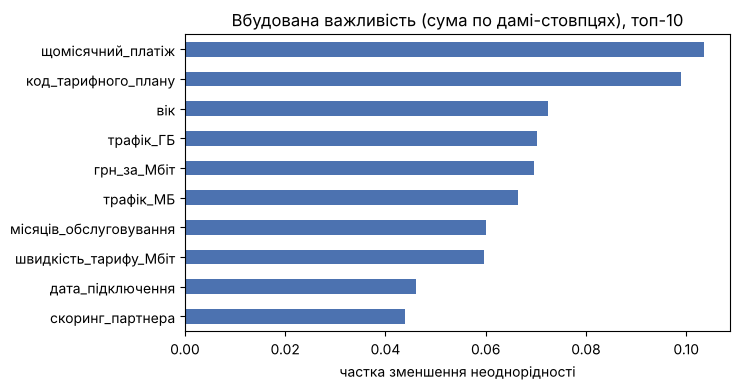

In [31]:
# ----- ВАШ КОД -----
# 1) дістаньте імена після перетворення: model.named_steps['prep'].get_feature_names_out()
names_t = model.named_steps['prep'].get_feature_names_out()


# 2) підсумуйте важливості дамі-стовпців до вихідних ознак
def original_names(prep):
    """Для кожного стовпця ПІСЛЯ перетворення — ім'я вихідної ознаки (усі дамі категорії -> одна ознака)."""
    out = []
    for name, tr, cols in prep.transformers_:
        if name == 'num':
            out += list(cols)
        elif name == 'cat':
            for col, levels in zip(cols, tr.named_steps['oh'].categories_):
                out += [col] * len(levels)      # категорія з k рівнями дає k стовпців 0/1
    return np.array(out)


orig_t = original_names(model.named_steps['prep'])
assert len(orig_t) == len(names_t)
gini_imp = (pd.Series(model.named_steps['clf'].feature_importances_, index=orig_t)
            .groupby(level=0).sum().sort_values(ascending=False))
print('стовпців після кодування: %d, з них дамі коду тарифного плану: %d'
      % (len(orig_t), (orig_t == 'код_тарифного_плану').sum()))

# 3) побудуйте горизонтальну стовпчикову діаграму топ-10
ax = gini_imp.head(10)[::-1].plot.barh(figsize=(7.5, 4), color='#4C72B0')
ax.set_title('Вбудована важливість (сума по дамі-стовпцях), топ-10')
ax.set_xlabel('частка зменшення неоднорідності')
plt.tight_layout(); plt.show()

### Завдання 9.2 — перестановочна важливість

Інший підхід: взяти навчену модель, **перемішати значення однієї ознаки**
у перевірковій частині й подивитись, наскільки впала якість. Впала сильно —
ознака потрібна; не впала — не потрібна.

Рахуйте на **перевірковій** частині: на навчальній перестановочна важливість
показує те саме перенавчання, що й вбудована.

In [32]:
perm = permutation_importance(model, Xte, yte, n_repeats=10,
                              random_state=SEED, scoring='roc_auc')
perm_imp = pd.Series(perm.importances_mean, index=FINAL_X.columns).sort_values(ascending=False)
display(perm_imp.head(10).to_frame('перестановочна важливість'))

,перестановочна важливість
щомісячний_платіж,0.058669
вік,0.052106
місяців_обслуговування,0.030929
швидкість_тарифу_Мбіт,0.015400
звернень_на_рік,0.013465
трафік_ГБ,0.012519
трафік_МБ,0.012299
спосіб_оплати,0.009198
кількість_послуг,0.004833
грн_за_Мбіт,0.003602


### Завдання 9.3 — ПЕРША ХИБНА ІНТЕРПРЕТАЦІЯ

Порівняйте два списки поруч. Знайдіть ознаку, яка:

* входить у **топ-5 за вбудованою** важливістю;
* має перестановочну важливість **близьку до нуля або від'ємну**.

Така ознака є в кожному варіанті. Знайдіть її, назвіть і поясніть, чому
вбудована важливість її переоцінює.

> **Підказка.** Згадайте, як дерево обирає розбиття. Ознака з великою
> кількістю різних значень дає дереву багато можливих порогів, тож вона
> майже завжди знаходить розбиття, яке трохи зменшує неоднорідність —
> навіть якщо жодного зв'язку з ціллю немає.

In [33]:
# ----- ВАШ КОД: таблиця «ознака | вбудована | перестановочна», відсортована за вбудованою -----
imp_cmp = pd.DataFrame({'вбудована': gini_imp, 'перестановочна': perm_imp,
                        '± перестановочної': pd.Series(perm.importances_std, index=FINAL_X.columns)})
imp_cmp['місце (вбуд.)'] = imp_cmp['вбудована'].rank(ascending=False).astype(int)
imp_cmp['місце (перест.)'] = imp_cmp['перестановочна'].rank(ascending=False).astype(int)
imp_cmp = imp_cmp.sort_values('вбудована', ascending=False).round(4)
imp_cmp.index.name = 'ознака'
display(imp_cmp)

,вбудована,перестановочна,± перестановочної,місце (вбуд.),місце (перест.)
ознака,,,,,
щомісячний_платіж,0.1036,0.0587,0.0112,1,1
код_тарифного_плану,0.0990,-0.0018,0.0032,2,22
вік,0.0724,0.0521,0.0048,3,2
трафік_ГБ,0.0702,0.0125,0.0060,4,6
грн_за_Мбіт,0.0696,0.0036,0.0079,5,10
трафік_МБ,0.0664,0.0123,0.0070,6,7
місяців_обслуговування,0.0600,0.0309,0.0075,7,3
швидкість_тарифу_Мбіт,0.0596,0.0154,0.0103,8,4
дата_підключення,0.0462,0.0015,0.0030,9,17


In [34]:
code_churn = raw.groupby('код_тарифного_плану')[TARGET].agg(['mean', 'size'])
tariffs_per_code = raw.groupby('код_тарифного_плану')['тариф'].nunique()
print('кодів: %d; клієнтів на код: %d–%d; різних тарифів в одному коді: %d–%d (тобто код не позначає тариф)'
      % (len(code_churn), code_churn['size'].min(), code_churn['size'].max(), tariffs_per_code.min(), tariffs_per_code.max()))
print('відтік по кодах від %.2f до %.2f — звичайний розкид малих груп по 20–40 людей навколо %.2f'
      % (code_churn['mean'].min(), code_churn['mean'].max(), y.mean()))
FAKE_IMPORTANT = 'код_тарифного_плану'        # назва ознаки
FAKE_IMPORTANT_WHY = ('за вбудованою важливістю ця ознака на %d-му місці (%.3f), а перестановочна на перевірковій частині %+.4f, '
                      'тобто без неї модель не гіршає. Це %d випадкових кодів по %d–%d клієнтів, не пов’язаних ні з тарифом, '
                      'ні з відтоком. Після кодування вони дають %d стовпців із %d, тож дерево на кожному вузлі має серед них '
                      'багато можливих розбиттів і майже завжди знаходить таке, що на навчальних даних випадково трохи '
                      'зменшує неоднорідність. Вбудована важливість рахується саме на навчальних даних і підсумовує ці '
                      'випадкові «покращення»; на нових клієнтах вони не повторюються.'
                      % (imp_cmp.loc[FAKE_IMPORTANT, 'місце (вбуд.)'], imp_cmp.loc[FAKE_IMPORTANT, 'вбудована'],
                         imp_cmp.loc[FAKE_IMPORTANT, 'перестановочна'], len(code_churn), code_churn['size'].min(),
                         code_churn['size'].max(), (orig_t == FAKE_IMPORTANT).sum(), len(orig_t)))
assert FAKE_IMPORTANT in FINAL_X.columns and FAKE_IMPORTANT_WHY
print('хибно важлива ознака:', FAKE_IMPORTANT)
print(FAKE_IMPORTANT_WHY)

кодів: 40; клієнтів на код: 20–40; різних тарифів в одному коді: 3–4 (тобто код не позначає тариф)
відтік по кодах від 0.07 до 0.46 — звичайний розкид малих груп по 20–40 людей навколо 0.26
хибно важлива ознака: код_тарифного_плану
за вбудованою важливістю ця ознака на 2-му місці (0.099), а перестановочна на перевірковій частині -0.0018, тобто без неї модель не гіршає. Це 40 випадкових кодів по 20–40 клієнтів, не пов’язаних ні з тарифом, ні з відтоком. Після кодування вони дають 40 стовпців із 76, тож дерево на кожному вузлі має серед них багато можливих розбиттів і майже завжди знаходить таке, що на навчальних даних випадково трохи зменшує неоднорідність. Вбудована важливість рахується саме на навчальних даних і підсумовує ці випадкові «покращення»; на нових клієнтах вони не повторюються.


### Завдання 9.4 — ДРУГА ХИБНА ІНТЕРПРЕТАЦІЯ

У наборі є **дві ознаки, які вимірюють те саме в різних одиницях**.
Знайдіть цю пару (підказка: подивіться на кореляції між числовими ознаками).

Потім перевірте, що з нею робить перестановочна важливість:

1. запишіть важливість обох ознак пари в повній моделі;
2. **приберіть одну** з них, навчіть модель заново і подивіться на важливість
   тієї, що лишилась.

Поясніть, що сталось і чому.

In [35]:
# ----- ВАШ КОД: кореляційна матриця числових ознак, знайдіть пару з |r| > 0.97 -----
num_cols = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
corr = FINAL_X[num_cols].corr()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))      # кожна пара — один раз
pairs = upper.stack().dropna().rename('r').reset_index()
pairs.columns = ['ознака 1', 'ознака 2', 'r']
pairs['|r|'] = pairs['r'].abs()
display(pairs.sort_values('|r|', ascending=False).head(5).round(4).reset_index(drop=True))
print('трафік_МБ / трафік_ГБ = %.0f (медіана): це той самий трафік, лише в мегабайтах (1 ГБ = 1024 МБ)'
      % (FINAL_X['трафік_МБ'] / FINAL_X['трафік_ГБ']).median())

,ознака 1,ознака 2,r,|r|
0,трафік_ГБ,трафік_МБ,0.9997,0.9997
1,швидкість_тарифу_Мбіт,щомісячний_платіж,0.7634,0.7634
2,середній_час_відповіді_хв,хвилин_очікування,0.7429,0.7429
3,кількість_звернень_у_підтримку,хвилин_очікування,0.6990,0.6990
4,швидкість_тарифу_Мбіт,грн_за_Мбіт,-0.6533,0.6533


трафік_МБ / трафік_ГБ = 1025 (медіана): це той самий трафік, лише в мегабайтах (1 ГБ = 1024 МБ)


In [36]:
DUP_PAIR = ['трафік_ГБ', 'трафік_МБ']        # дві ознаки, що вимірюють те саме
assert all(c in FINAL_X.columns for c in DUP_PAIR) and DUP_PAIR[0] != DUP_PAIR[1]

print('у повній моделі:')
for c in DUP_PAIR:
    print('   %-28s %+.4f' % (c, perm_imp[c]))

# ----- ВАШ КОД: приберіть DUP_PAIR[1], навчіть заново, порахуйте перестановочну -----
# і виведіть важливість DUP_PAIR[0] без пари
X_nodup = FINAL_X.drop(columns=[DUP_PAIR[1]])
Xtr_nd, Xte_nd = Xtr.drop(columns=[DUP_PAIR[1]]), Xte.drop(columns=[DUP_PAIR[1]])    # ті самі рядки, що й раніше
model_nodup = make_pipe(X_nodup, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)).fit(Xtr_nd, ytr)
perm_nd = permutation_importance(model_nodup, Xte_nd, yte, n_repeats=10, random_state=SEED, scoring='roc_auc')
perm_imp_nodup = pd.Series(perm_nd.importances_mean, index=X_nodup.columns)
auc_hold_nodup = roc_auc_score(yte, model_nodup.predict_proba(Xte_nd)[:, 1])
print('без %s:' % DUP_PAIR[1])
print('   %-28s %+.4f   (у %.1f раза більше, ніж у парі)'
      % (DUP_PAIR[0], perm_imp_nodup[DUP_PAIR[0]], perm_imp_nodup[DUP_PAIR[0]] / perm_imp[DUP_PAIR[0]]))
print('AUC на відкладеній частині: з парою %.3f, без %s %.3f' % (auc_hold, DUP_PAIR[1], auc_hold_nodup))

у повній моделі:
   трафік_ГБ                    +0.0125
   трафік_МБ                    +0.0123
без трафік_МБ:
   трафік_ГБ                    +0.0465   (у 3.7 раза більше, ніж у парі)
AUC на відкладеній частині: з парою 0.829, без трафік_МБ 0.830


In [37]:
DUP_EXPLANATION = ('%s і %s — той самий трафік у різних одиницях (r = %.4f). У повній моделі в обох скромна '
                   'перестановочна важливість (%.4f і %.4f): коли перемішуємо одну, модель бере ту саму інформацію з другої. '
                   'Коли %s прибрали й навчили модель заново, важливість %s зросла до %.4f, у %.1f раза, а AUC майже не '
                   'змінилась (%.3f -> %.3f). Метод не бреше: він чесно відповідає, наскільки гірше стане без ОДНІЄЇ ознаки, '
                   'а без однієї з двох копій майже не гірше. Хибним є висновок «важливість мала, отже трафік неважливий».'
                   % (DUP_PAIR[0], DUP_PAIR[1], corr.loc[DUP_PAIR[0], DUP_PAIR[1]], perm_imp[DUP_PAIR[0]], perm_imp[DUP_PAIR[1]],
                      DUP_PAIR[1], DUP_PAIR[0], perm_imp_nodup[DUP_PAIR[0]], perm_imp_nodup[DUP_PAIR[0]] / perm_imp[DUP_PAIR[0]],
                      auc_hold, auc_hold_nodup))
assert DUP_EXPLANATION
print(DUP_EXPLANATION)

трафік_ГБ і трафік_МБ — той самий трафік у різних одиницях (r = 0.9997). У повній моделі в обох скромна перестановочна важливість (0.0125 і 0.0123): коли перемішуємо одну, модель бере ту саму інформацію з другої. Коли трафік_МБ прибрали й навчили модель заново, важливість трафік_ГБ зросла до 0.0465, у 3.7 раза, а AUC майже не змінилась (0.829 -> 0.830). Метод не бреше: він чесно відповідає, наскільки гірше стане без ОДНІЄЇ ознаки, а без однієї з двох копій майже не гірше. Хибним є висновок «важливість мала, отже трафік неважливий».


> **Що тут сталося.** Перестановочна важливість відповідає на питання
> «наскільки модель погіршиться **без цієї ознаки**». Коли та сама інформація
> є у двох колонках, перемішування однієї нічого не ламає: модель бере її
> з другої. Обидві виглядають непотрібними — хоча разом вони важливі.
>
> Це не вада методу, а точна відповідь на поставлене питання. Вада —
> в інтерпретації «важливість нуль, отже ознаку можна викинути».

---
## 10. Графіки часткової залежності

Важливість каже, **наскільки** ознака потрібна. Вона не каже, **як саме**
ознака впливає: більше — ризикованіше чи навпаки.

**Графік часткової залежності (PDP)** будується так: беремо всю вибірку,
підставляємо всім клієнтам одне й те саме значення ознаки, усереднюємо
прогноз; повторюємо для сітки значень.

### Завдання 10.1

Побудуйте PDP для трьох найважливіших **числових** ознак за перестановочною
важливістю. Для кожної скажіть словами, що означає форма кривої.

три найважливіші числові ознаки за перестановочною важливістю: ['щомісячний_платіж', 'вік', 'місяців_обслуговування']


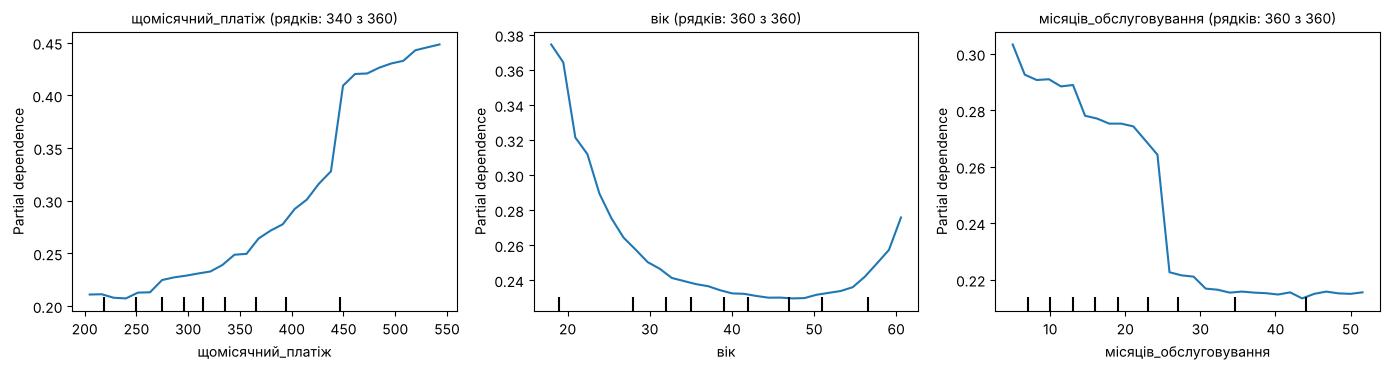

щомісячний_платіж        зростає: 0.211 -> 0.448 (максимум при 543)
вік                      спадає, потім зростає: 0.375 -> мінімум 0.230 при 47 -> 0.276
місяців_обслуговування   спадає: 0.303 -> 0.216 (мінімум при 44)
   -> щомісячний_платіж: чим дорожчий тариф, тим вищий ризик; найрізкіший стрибок — біля 450 грн: дорогий тариф легко поміняти на дешевший
   -> вік: «яма»: найризикованіші наймолодші, найнадійніші — люди середнього віку, після 55 ризик знову зростає
   -> місяців_обслуговування: нові клієнти ризикованіші; приблизно після 2 років ризик різко падає і далі не змінюється — хто протримався два роки, той звик
пропуски: у щомісячний_платіж PDP побудовано на 340 рядках, де ознака заповнена; в інших ознаках пропусків немає


In [38]:
from sklearn.inspection import PartialDependenceDisplay


def pdp_curve(estimator, X, feature, grid_resolution=100):
    """PDP однієї ознаки: (сітка значень, середній прогнозований ризик)."""
    r = partial_dependence(estimator, X, [feature], kind='average', grid_resolution=grid_resolution)
    grid = r['grid_values'][0] if 'grid_values' in r else r['values'][0]     # назва ключа залежить від версії sklearn
    return np.asarray(grid, dtype=float), np.asarray(r['average'][0])


def describe_shape(grid, curve):
    """Словами: як змінюється ризик уздовж ознаки."""
    i_min, i_max = int(np.argmin(curve)), int(np.argmax(curve))
    if 0 < i_min < len(curve) - 1 and min(curve[0], curve[-1]) - curve[i_min] > 0.02:
        return 'спадає, потім зростає: %.3f -> мінімум %.3f при %.0f -> %.3f' % (curve[0], curve[i_min], grid[i_min], curve[-1])
    if curve[-1] > curve[0]:
        return 'зростає: %.3f -> %.3f (максимум при %.0f)' % (curve[0], curve[-1], grid[i_max])
    return 'спадає: %.3f -> %.3f (мінімум при %.0f)' % (curve[0], curve[-1], grid[i_min])


# ----- ВАШ КОД -----
num_feats = [c for c in FINAL_X.columns if str(FINAL_X[c].dtype) != 'category']
TOP3_NUM = perm_imp[num_feats].sort_values(ascending=False).head(3).index.tolist()
print('три найважливіші числові ознаки за перестановочною важливістю:', TOP3_NUM)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
pdp_shapes = {}
for ax, c in zip(axes, TOP3_NUM):
    mask = Xte[c].notna()          # ознака з пропусками дала б порожню сітку — беремо рядки, де вона заповнена
    PartialDependenceDisplay.from_estimator(model, Xte[mask], features=[c], kind='average', grid_resolution=30, ax=ax)
    ax.set_title('%s (рядків: %d з %d)' % (c, mask.sum(), len(Xte)), fontsize=10)
    pdp_shapes[c] = describe_shape(*pdp_curve(model, Xte[mask], c, grid_resolution=30))
plt.tight_layout(); plt.show()
for c in TOP3_NUM:
    print('%-24s %s' % (c, pdp_shapes[c]))
PDP_MEANING = {
    'щомісячний_платіж': 'чим дорожчий тариф, тим вищий ризик; найрізкіший стрибок — біля 450 грн: дорогий тариф легко поміняти на дешевший',
    'вік': '«яма»: найризикованіші наймолодші, найнадійніші — люди середнього віку, після 55 ризик знову зростає',
    'місяців_обслуговування': 'нові клієнти ризикованіші; приблизно після 2 років ризик різко падає і далі не змінюється — хто протримався два роки, той звик',
}
for c in TOP3_NUM:
    print('   -> %s: %s' % (c, PDP_MEANING.get(c, '')))
print('пропуски: у %s PDP побудовано на %d рядках, де ознака заповнена; в інших ознаках пропусків немає'
      % (TOP3_NUM[0], Xte[TOP3_NUM[0]].notna().sum()) if Xte[TOP3_NUM[0]].isna().any() else '')

### Завдання 10.2 — немонотонна залежність

Серед ознак є така, у якої PDP **не монотонний**: ризик спадає, а потім
знову зростає (або навпаки). Знайдіть її.

Лінійна модель такої залежності не бачить **за побудовою**: вона може лише
зростати або лише спадати. Перевірте це: порівняйте PDP лісу й логістичної
регресії на тій самій ознаці, на одному рисунку.

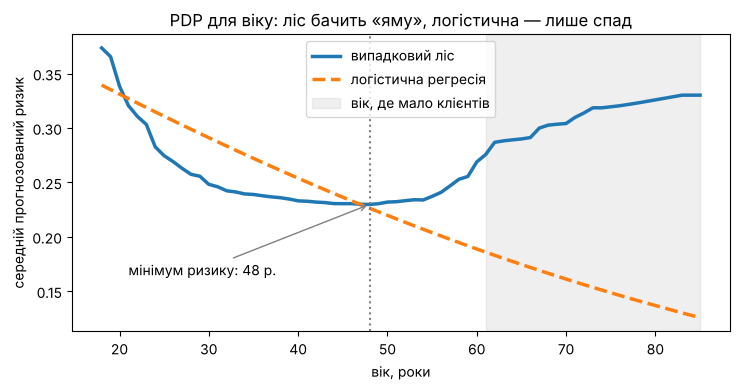

ліс       : спадає, потім зростає: 0.374 -> мінімум 0.230 при 48 -> 0.276
логістична: спадає: 0.339 -> 0.186 (мінімум при 61)
(описано для віку 18–61: у цьому проміжку 90 % клієнтів)


вік,18–23,24–30,31–40,41–50,51–55,56+
частка_відтоку,0.491,0.278,0.223,0.161,0.168,0.324
клієнтів,159.000,151.000,359.000,285.000,101.000,145.000


In [39]:
NONLINEAR_FEATURE = 'вік'
assert NONLINEAR_FEATURE in FINAL_X.columns

# ----- ВАШ КОД: один рисунок, дві криві — ліс і логістична регресія -----
lr_model = make_pipe(FINAL_X, logreg()).fit(Xtr, ytr)            # логістична регресія на тих самих навчальних рядках
g_rf, pd_rf = pdp_curve(model, FINAL_X, NONLINEAR_FEATURE)       # PDP — опитування моделі, тож беремо всі рядки
g_lr, pd_lr = pdp_curve(lr_model, FINAL_X, NONLINEAR_FEATURE)
age_lo, age_hi = np.percentile(FINAL_X[NONLINEAR_FEATURE], [5, 95])   # де клієнтів достатньо
inside = (g_rf >= age_lo) & (g_rf <= age_hi)
AGE_BEST = int(round(g_rf[inside][np.argmin(pd_rf[inside])]))     # вік із найменшим ризиком (за лісом)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(g_rf, pd_rf, lw=2.5, label='випадковий ліс')
ax.plot(g_lr, pd_lr, lw=2.5, ls='--', label='логістична регресія')
ax.axvline(AGE_BEST, color='grey', ls=':', lw=1.5)
ax.axvspan(g_rf.min(), age_lo, color='grey', alpha=0.12, lw=0)
ax.axvspan(age_hi, g_rf.max(), color='grey', alpha=0.12, label='вік, де мало клієнтів')
ax.annotate('мінімум ризику: %d р.' % AGE_BEST, xy=(AGE_BEST, pd_rf[inside].min()), xytext=(21, pd_rf[inside].min() - 0.065),
            arrowprops=dict(arrowstyle='->', color='grey'))
ax.set_xlabel('вік, роки'); ax.set_ylabel('середній прогнозований ризик')
ax.set_title('PDP для віку: ліс бачить «яму», логістична — лише спад'); ax.legend(loc='upper center')
plt.tight_layout(); plt.show()

print('ліс       : %s' % describe_shape(g_rf[inside], pd_rf[inside]))
print('логістична: %s' % describe_shape(g_lr[inside], pd_lr[inside]))
print('(описано для віку %.0f–%.0f: у цьому проміжку 90 %% клієнтів)' % (age_lo, age_hi))
age_bins = pd.cut(raw['вік'], [17, 23, 30, 40, 50, 55, 90], labels=['18–23', '24–30', '31–40', '41–50', '51–55', '56+'])
age_emp = raw.groupby(age_bins, observed=True)[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
display(age_emp.T)

In [40]:
NONLINEAR_MEANING = ('ризик найвищий у наймолодших (18–23 роки: відтік %.0f %%), найнижчий у людей близько %d років '
                     '(41–50: %.0f %%) і знову зростає після 55 (%.0f %%). Молоді частіше переїжджають і шукають дешевше, '
                     'а старші, ймовірно, відмовляються від послуги або переходять на простішу; люди середнього віку '
                     '— найстабільніші абоненти.'
                     % (100 * age_emp.loc['18–23', 'частка_відтоку'], AGE_BEST, 100 * age_emp.loc['41–50', 'частка_відтоку'],
                        100 * age_emp.loc['56+', 'частка_відтоку']))
NONLINEAR_FIX = ('додати ознаку (вік − %d)² — квадрат відхилення від віку з найменшим ризиком: вона мала біля %d років '
                 'і велика і для молодих, і для старших, тож лінійна модель зможе описати «яму» одним коефіцієнтом.'
                 % (AGE_BEST, AGE_BEST))
assert NONLINEAR_MEANING and NONLINEAR_FIX
print(NONLINEAR_MEANING)
print(NONLINEAR_FIX)

ризик найвищий у наймолодших (18–23 роки: відтік 49 %), найнижчий у людей близько 48 років (41–50: 16 %) і знову зростає після 55 (32 %). Молоді частіше переїжджають і шукають дешевше, а старші, ймовірно, відмовляються від послуги або переходять на простішу; люди середнього віку — найстабільніші абоненти.
додати ознаку (вік − 48)² — квадрат відхилення від віку з найменшим ризиком: вона мала біля 48 років і велика і для молодих, і для старших, тож лінійна модель зможе описати «яму» одним коефіцієнтом.


### Завдання 10.2б — замкніть цикл

Пояснення моделі має **повертатись у підготовку даних**. PDP показав форму —
тепер побудуйте ознаку цієї форми і виміряйте, що вона дала.

Зробіть це для **логістичної регресії**, а не для лісу: ліс цю форму і так
бачив, а лінійна модель — ні. Порівняння має бути парним.

In [41]:
# ----- ВАШ КОД -----
# 1) зчитайте з графіка значення, при якому ризик мінімальний;
print('мінімум ризику на PDP лісу: %d років' % AGE_BEST)


# 2) додайте ознаку «квадрат відхилення від цього значення»;
def add_quad(X):
    F = X.copy()
    F['вік_відхилення_кв'] = (F[NONLINEAR_FEATURE] - AGE_BEST) ** 2
    return F


X_quad = add_quad(FINAL_X)

# 3) парне порівняння логістичної регресії з нею і без неї.
lr_base = cross_val_score(make_pipe(FINAL_X, logreg()), FINAL_X, y, cv=cv, scoring='roc_auc')
lr_quad = cross_val_score(make_pipe(X_quad, logreg()), X_quad, y, cv=cv, scoring='roc_auc')
m_q, h_q = paired(lr_base, lr_quad)
print('логістична без ознаки: AUC %.3f ± %.3f' % (lr_base.mean(), lr_base.std()))
print('логістична з ознакою : AUC %.3f ± %.3f' % (lr_quad.mean(), lr_quad.std()))
print('приріст: %+.4f ± %.4f   %s' % (m_q, h_q, 'значуще' if abs(m_q) > h_q else 'у межах шуму'))

# контроль: лісу та сама ознака не дає нічого — він цю форму і так бачив
rf_base = cross_val_score(make_pipe(FINAL_X, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
                          FINAL_X, y, cv=cv, scoring='roc_auc')
rf_quad = cross_val_score(make_pipe(X_quad, RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1)),
                          X_quad, y, cv=cv, scoring='roc_auc')
m_rfq, h_rfq = paired(rf_base, rf_quad)
print('ліс     : %.3f -> %.3f, приріст %+.4f ± %.4f   %s'
      % (rf_base.mean(), rf_quad.mean(), m_rfq, h_rfq, 'значуще' if abs(m_rfq) > h_rfq else 'у межах шуму'))

мінімум ризику на PDP лісу: 48 років
логістична без ознаки: AUC 0.819 ± 0.023
логістична з ознакою : AUC 0.856 ± 0.025
приріст: +0.0376 ± 0.0073   значуще
ліс     : 0.830 -> 0.833, приріст +0.0032 ± 0.0040   у межах шуму


In [42]:
QUAD_GAIN = float(m_q)     # приріст AUC лінійної моделі від нової ознаки
assert QUAD_GAIN is not None
print('приріст від сконструйованої ознаки: %+.4f' % QUAD_GAIN)

приріст від сконструйованої ознаки: +0.0376


### Завдання 10.3 — ТРЕТЯ ХИБНА ІНТЕРПРЕТАЦІЯ

PDP **усереднює по всій вибірці**. Якщо ознака діє на різні групи клієнтів
по-різному, усереднення це приховає: протилежні ефекти взаємно погасяться,
і крива вийде майже пласкою.

Перевірте це на парі «знижка — стаж обслуговування».

1. Побудуйте звичайний PDP для `знижка_відсоток` по всій вибірці.
2. Побудуйте **ICE** (`kind='individual'`) — по кривій на кожного клієнта.
   Подивіться, чи всі криві йдуть в один бік.
3. Побудуйте PDP для `знижка_відсоток` **окремо** на двох підвибірках:
   клієнти зі стажем до 24 місяців і понад 24 місяці.

> **Важливо.** PDP і ICE рахуйте на **повній** матриці `FINAL_X`,
> а не на `Xte`. Це опитування моделі, а не оцінювання якості, тож
> використовувати всі рядки коректно — а на 30 % рядків підгрупи виходять
> замалі й криві стають шумними.

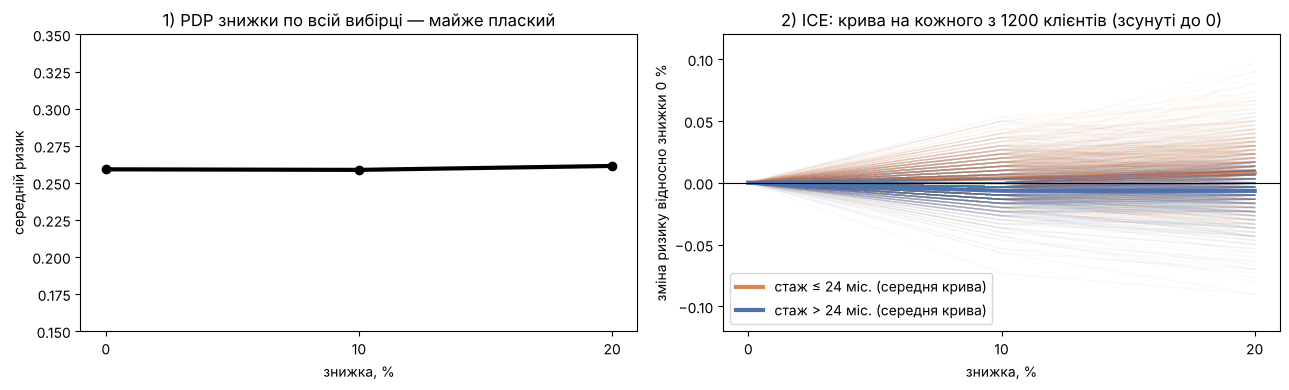

PDP по всій вибірці: 0.259 -> 0.259 -> 0.261
ICE: ризик зростає зі знижкою в 199 клієнтів, спадає в 146, майже не змінюється (|зміна| ≤ 0.02) у 855
середня зміна від 0 до 20 %: стаж ≤ 24 міс. +0.008, стаж > 24 міс. -0.007


In [43]:
# ----- ВАШ КОД: пункт 1 і 2, PDP та ICE для 'знижка_відсоток' -----
DISC = 'знижка_відсоток'
r_disc = partial_dependence(model, FINAL_X, [DISC], kind='both')    # 'both' = середнє (PDP) і криві клієнтів (ICE)
grid_d = np.asarray(r_disc['grid_values'][0] if 'grid_values' in r_disc else r_disc['values'][0], dtype=float)
pdp_all = r_disc['average'][0]
ice = r_disc['individual'][0]                        # рядок = клієнт, стовпець = значення знижки
ice_c = ice - ice[:, [0]]                            # кожну криву зсуваємо так, щоб вона починалась з 0
young = (FINAL_X['місяців_обслуговування'] <= 24).values     # стаж до 24 місяців включно

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(grid_d, pdp_all, 'k-o', lw=3)
ax[0].set_ylim(0.15, 0.35); ax[0].set_xticks(grid_d)
ax[0].set_title('1) PDP знижки по всій вибірці — майже плаский'); ax[0].set_xlabel('знижка, %'); ax[0].set_ylabel('середній ризик')
for grp, color, lbl in [(young, '#DD8452', 'стаж ≤ 24 міс.'), (~young, '#4C72B0', 'стаж > 24 міс.')]:
    ax[1].plot(grid_d, ice_c[grp].T, color=color, alpha=0.04, lw=1)
    ax[1].plot(grid_d, ice_c[grp].mean(axis=0), color=color, lw=3, label=lbl + ' (середня крива)')
ax[1].axhline(0, color='k', lw=0.8)
ax[1].set_xticks(grid_d); ax[1].set_ylim(-0.12, 0.12); ax[1].legend(loc='lower left')
ax[1].set_title('2) ICE: крива на кожного з %d клієнтів (зсунуті до 0)' % len(ice))
ax[1].set_xlabel('знижка, %'); ax[1].set_ylabel('зміна ризику відносно знижки 0 %')
plt.tight_layout(); plt.show()

slope = ice[:, -1] - ice[:, 0]               # як змінюється ризик клієнта від знижки 0 % до 20 %
print('PDP по всій вибірці: %s' % ' -> '.join('%.3f' % v for v in pdp_all))
print('ICE: ризик зростає зі знижкою в %d клієнтів, спадає в %d, майже не змінюється (|зміна| ≤ 0.02) у %d'
      % ((slope > 0.02).sum(), (slope < -0.02).sum(), (np.abs(slope) <= 0.02).sum()))
print('середня зміна від 0 до 20 %%: стаж ≤ 24 міс. %+.3f, стаж > 24 міс. %+.3f' % (slope[young].mean(), slope[~young].mean()))

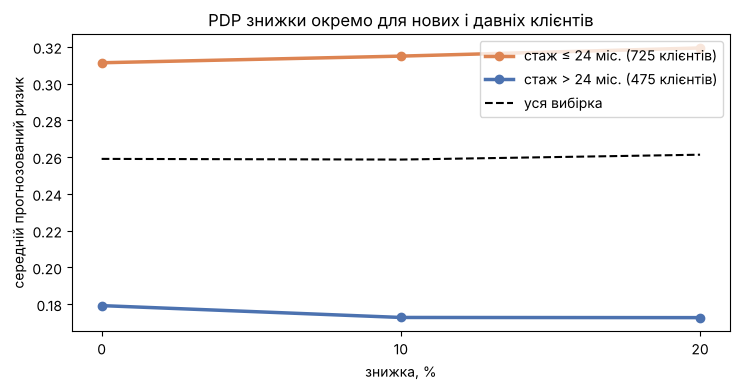

модель, стаж ≤ 24: 0.311 -> 0.315 -> 0.319
модель, стаж > 24: 0.179 -> 0.173 -> 0.173


In [44]:
# ----- ВАШ КОД: пункт 3, дві криві на одному рисунку -----
# підказка: partial_dependence(model, FINAL_X[mask], ['знижка_відсоток'], kind='average')
g_y, pdp_young = pdp_curve(model, FINAL_X[young], DISC)
g_o, pdp_old = pdp_curve(model, FINAL_X[~young], DISC)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(g_y, pdp_young, 'o-', color='#DD8452', lw=2.5, label='стаж ≤ 24 міс. (%d клієнтів)' % young.sum())
ax.plot(g_o, pdp_old, 'o-', color='#4C72B0', lw=2.5, label='стаж > 24 міс. (%d клієнтів)' % (~young).sum())
ax.plot(grid_d, pdp_all, 'k--', lw=1.5, label='уся вибірка')
ax.set_xticks(grid_d); ax.set_xlabel('знижка, %'); ax.set_ylabel('середній прогнозований ризик')
ax.set_title('PDP знижки окремо для нових і давніх клієнтів'); ax.legend()
plt.tight_layout(); plt.show()
print('модель, стаж ≤ 24: %s' % ' -> '.join('%.3f' % v for v in pdp_young))
print('модель, стаж > 24: %s' % ' -> '.join('%.3f' % v for v in pdp_old))

### Завдання 10.3б — звірка з сирими даними

Перш ніж вірити графіку, перевірте його по сирій таблиці: порахуйте
**емпіричну** частку відтоку за розміром знижки окремо в кожній групі стажу.
Модель має відтворювати ту саму картину. Якщо не відтворює — питання
не до PDP, а до моделі.

In [45]:
# ----- ВАШ КОД: зведена таблиця «знижка x група стажу» -> частка відтоку і розмір групи -----
tenure_grp = pd.Series(np.where(raw['місяців_обслуговування'] <= 24, 'стаж ≤ 24 міс.', 'стаж > 24 міс.'),
                       index=raw.index, name='група стажу')
emp = raw.groupby([tenure_grp, DISC])[TARGET].agg(частка_відтоку='mean', клієнтів='size').round(3)
emp_tab = emp.unstack(0)
display(emp_tab)

# поруч: сирі дані і модель (PDP по підгрупах)
check = pd.DataFrame({'сирі дані, ≤ 24': emp_tab[('частка_відтоку', 'стаж ≤ 24 міс.')].values, 'модель, ≤ 24': pdp_young,
                      'сирі дані, > 24': emp_tab[('частка_відтоку', 'стаж > 24 міс.')].values, 'модель, > 24': pdp_old},
                     index=pd.Index(grid_d.astype(int), name='знижка, %')).round(3)
display(check)
emp_y = emp_tab[('частка_відтоку', 'стаж ≤ 24 міс.')]
emp_o = emp_tab[('частка_відтоку', 'стаж > 24 міс.')]
print('сирі дані: від знижки 0 до 20 %% відтік нових %+.3f, давніх %+.3f; модель: %+.3f і %+.3f'
      % (emp_y.iloc[-1] - emp_y.iloc[0], emp_o.iloc[-1] - emp_o.iloc[0],
         pdp_young[-1] - pdp_young[0], pdp_old[-1] - pdp_old[0]))

частка_відтоку                      клієнтів               
група стажу     стаж > 24 міс. стаж ≤ 24 міс. стаж > 24 міс. стаж ≤ 24 міс.
знижка_відсоток                                                            
0                        0.208          0.271            178            288
10                       0.100          0.363            150            237
20                       0.102          0.395            147            200

,"сирі дані, ≤ 24","модель, ≤ 24","сирі дані, > 24","модель, > 24"
"знижка, %",,,,
0,0.271,0.311,0.208,0.179
10,0.363,0.315,0.100,0.173
20,0.395,0.319,0.102,0.173


сирі дані: від знижки 0 до 20 % відтік нових +0.124, давніх -0.106; модель: +0.008 і -0.007


In [46]:
INTERACTION_FOUND = ('знижка діє на дві групи в протилежні боки, тому PDP по всій вибірці плаский (%.3f -> %.3f). '
                     'У нових клієнтів (стаж ≤ 24 міс.) відтік зі знижкою зростає: %.0f %% без знижки, %.0f %% при 10 %%, '
                     '%.0f %% при 20 %%; у давніх (> 24 міс.) — падає: %.0f %% -> %.0f %% -> %.0f %%. Модель бачить той самий '
                     'напрям (%+.3f і %+.3f), але сильно його занижує, тож тут «питання до моделі»: ліс майже не '
                     'користується знижкою (вбудована важливість %.3f — %d-те місце з %d).'
                     % (pdp_all[0], pdp_all[-1], *(100 * emp_y.values), *(100 * emp_o.values),
                        pdp_young[-1] - pdp_young[0], pdp_old[-1] - pdp_old[0], gini_imp[DISC],
                        imp_cmp.loc[DISC, 'місце (вбуд.)'], len(imp_cmp)))
BUSINESS_ACTION = ('пропонувати знижку при обдзвоні варто давнім клієнтам (стаж понад 2 роки): серед них зі знижкою йде '
                   'удвічі менше (%.0f %% проти %.0f %%). Новим клієнтам знижка не допомагає — їм потрібне інше '
                   '(швидка підтримка, відповідний тариф). Це зв’язок, а не доведена причина, тож перед масовим '
                   'запуском правило варто перевірити на невеликій контрольній групі.'
                   % (100 * emp_o.iloc[-1], 100 * emp_o.iloc[0]))
assert INTERACTION_FOUND and BUSINESS_ACTION
print(INTERACTION_FOUND)
print(BUSINESS_ACTION)

знижка діє на дві групи в протилежні боки, тому PDP по всій вибірці плаский (0.259 -> 0.261). У нових клієнтів (стаж ≤ 24 міс.) відтік зі знижкою зростає: 27 % без знижки, 36 % при 10 %, 40 % при 20 %; у давніх (> 24 міс.) — падає: 21 % -> 10 % -> 10 %. Модель бачить той самий напрям (+0.008 і -0.007), але сильно його занижує, тож тут «питання до моделі»: ліс майже не користується знижкою (вбудована важливість 0.013 — 22-те місце з 23).
пропонувати знижку при обдзвоні варто давнім клієнтам (стаж понад 2 роки): серед них зі знижкою йде удвічі менше (10 % проти 21 %). Новим клієнтам знижка не допомагає — їм потрібне інше (швидка підтримка, відповідний тариф). Це зв’язок, а не доведена причина, тож перед масовим запуском правило варто перевірити на невеликій контрольній групі.


> **Що тут сталося.** PDP відповідає на питання «як змінюється
> **середній** прогноз». Якщо ефект різноспрямований, середнє близьке до нуля
> при сильних ефектах у кожній групі. ICE показує окремі криві й робить
> розбіжність видимою; PDP по підгрупах показує її кількісно.

---
## 11. Значення Шеплі

Важливість і PDP описують модель **загалом**. Відділу утримання потрібне
інше: чому **цей** клієнт отримав оцінку 0,8.

**Значення Шеплі** (SHAP) розкладають прогноз для одного об'єкта на внески
окремих ознак так, щоб сума внесків плюс базовий рівень дорівнювала самому
прогнозу. Ідея запозичена з теорії кооперативних ігор: внесок гравця —
це його середній приріст до результату по всіх можливих складах команди.

### Завдання 11.1

Порахуйте значення Шеплі для вашої моделі на перевірковій частині.

> `TreeExplainer` працює з деревами і хоче **числову матрицю**, тому
> подавайте йому вже перетворені дані: `model.named_steps['prep'].transform(Xte)`.

In [47]:
import shap

prep = model.named_steps['prep']
clf = model.named_steps['clf']
Xte_t = prep.transform(Xte)
feat_names = prep.get_feature_names_out()

SAMPLE = min(300, Xte_t.shape[0])      # щоб рахувалось за секунди
expl = shap.TreeExplainer(clf)
sv = expl.shap_values(Xte_t[:SAMPLE])
# стара версія shap повертає список [клас 0, клас 1], нова — масив (клієнти, ознаки, класи)
sv1 = sv[1] if isinstance(sv, list) else (sv[..., 1] if np.ndim(sv) == 3 else sv)
base_value = float(np.ravel(expl.expected_value)[-1])    # базовий рівень = середній ризик
print('матриця значень Шеплі:', np.shape(sv1))
print('базовий рівень (середній прогноз): %.3f' % base_value)

матриця значень Шеплі: (300, 76)
базовий рівень (середній прогноз): 0.258


### Завдання 11.2 — зведений графік

Побудуйте `beeswarm` (`shap.summary_plot`). Прочитайте з нього дві речі,
яких **не дає** стовпчикова діаграма важливості:

* у який бік діє ознака (колір — значення ознаки, вісь — внесок);
* чи однаковий цей напрям для всіх клієнтів.

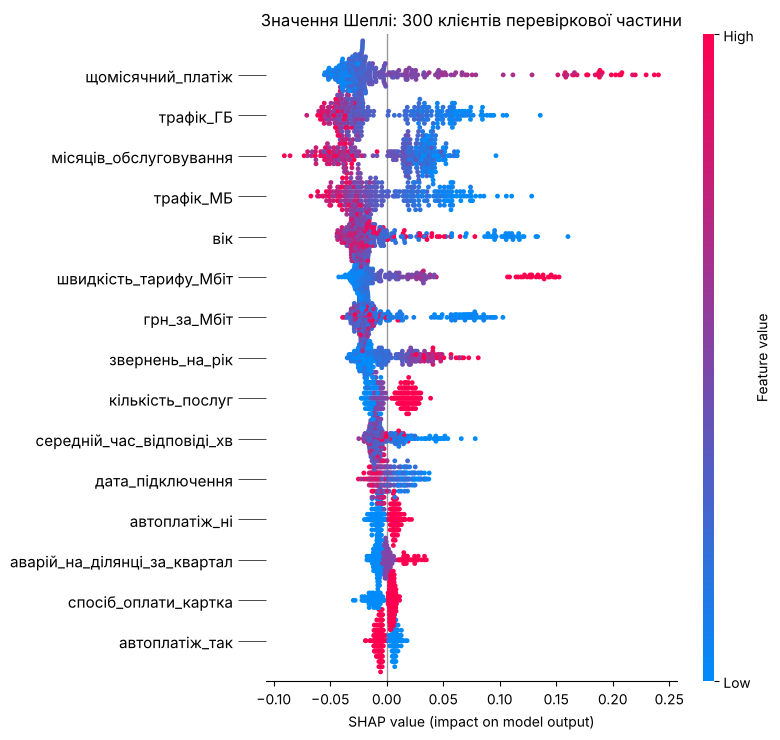

,середній |внесок|,зв’язок «значення — внесок»,напрям
ознака,,,
щомісячний_платіж,0.0438,0.95,більше -> ризик вищий
трафік_ГБ,0.0409,-0.93,більше -> ризик нижчий
місяців_обслуговування,0.0353,-0.89,більше -> ризик нижчий
трафік_МБ,0.0337,-0.96,більше -> ризик нижчий
вік,0.0323,-0.49,різний у різних клієнтів
швидкість_тарифу_Мбіт,0.0308,0.92,більше -> ризик вищий
грн_за_Мбіт,0.0282,-0.67,більше -> ризик нижчий
звернень_на_рік,0.0215,0.88,більше -> ризик вищий


In [48]:
# ----- ВАШ КОД: shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_names) -----
feat_clean = [n.split('__', 1)[1] for n in feat_names]      # 'num__вік' -> 'вік', 'cat__автоплатіж_ні' -> 'автоплатіж_ні'
shap.summary_plot(sv1, Xte_t[:SAMPLE], feature_names=feat_clean, max_display=15, show=False)
plt.title('Значення Шеплі: %d клієнтів перевіркової частини' % SAMPLE)
plt.tight_layout(); plt.show()

# дві речі, яких не дає стовпчикова діаграма: напрям дії і чи однаковий він для всіх
mean_abs = pd.Series(np.abs(sv1).mean(axis=0), index=feat_clean).sort_values(ascending=False)
direction = []
for f in mean_abs.index[:8]:
    j = feat_clean.index(f)
    rho = pd.Series(Xte_t[:SAMPLE, j]).corr(pd.Series(sv1[:, j]), method='spearman')
    direction.append({'ознака': f, 'середній |внесок|': round(mean_abs[f], 4),
                      'зв’язок «значення — внесок»': round(rho, 2),
                      'напрям': ('—' if np.isnan(rho) else 'більше -> ризик вищий' if rho > 0.6
                                 else 'більше -> ризик нижчий' if rho < -0.6 else 'різний у різних клієнтів')})
display(pd.DataFrame(direction).set_index('ознака'))

### Завдання 11.3 — пояснення для одного клієнта

Відділ утримання телефонує конкретній людині. Візьміть клієнта з
**найвищою** оцінкою ризику і поясніть його прогноз: які три ознаки
внесли найбільше і в який бік.

Напишіть пояснення **мовою, якою його можна прочитати менеджерові**, —
без назв стовпців і без слова «модель».

ризик клієнта: 0.860


,ознака,значення в клієнта,внесок
0,щомісячний_платіж,673.4,0.1657
1,швидкість_тарифу_Мбіт,1000.0,0.1208
2,грн_за_Мбіт,0.6734,0.0779


перевірка суми: базовий рівень 0.258 + сума всіх внесків +0.602 = 0.860 (прогноз 0.860)


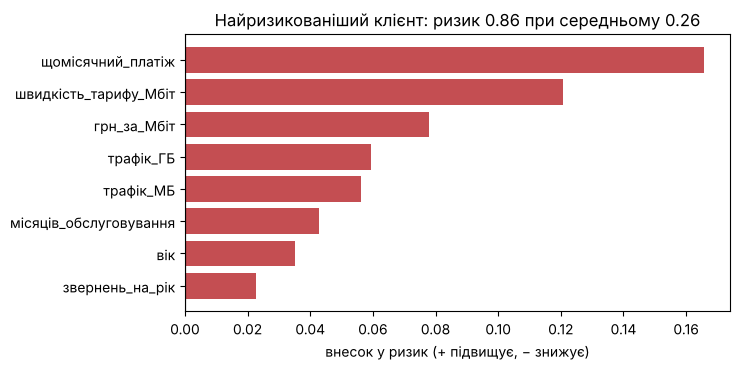

,вік,місяців_обслуговування,тариф,швидкість_тарифу_Мбіт,щомісячний_платіж,трафік_ГБ,знижка_відсоток,автоплатіж
клієнт,22.0,9.0,оптимальний,1000.0,673.4,75.3,10.0,ні


In [49]:
idx = int(np.argmax(model.predict_proba(Xte)[:SAMPLE, 1]))
print('ризик клієнта: %.3f' % model.predict_proba(Xte)[:SAMPLE, 1][idx])

# ----- ВАШ КОД: три найбільші за модулем внески для цього клієнта -----
client = Xte.iloc[idx]
risk_client = model.predict_proba(Xte)[:SAMPLE, 1][idx]
contrib = pd.DataFrame({'ознака': feat_clean, 'вихідна ознака': orig_t, 'внесок': sv1[idx]})
contrib['значення в клієнта'] = [client[o] for o in contrib['вихідна ознака']]
contrib = contrib.reindex(contrib['внесок'].abs().sort_values(ascending=False).index).reset_index(drop=True)
display(contrib.head(3)[['ознака', 'значення в клієнта', 'внесок']].round(4))
print('перевірка суми: базовий рівень %.3f + сума всіх внесків %+.3f = %.3f (прогноз %.3f)'
      % (base_value, sv1[idx].sum(), base_value + sv1[idx].sum(), risk_client))

top8 = contrib.head(8)[::-1]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.barh(top8['ознака'], top8['внесок'], color=np.where(top8['внесок'] > 0, '#C44E52', '#4C72B0'))
ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('внесок у ризик (+ підвищує, − знижує)')
ax.set_title('Найризикованіший клієнт: ризик %.2f при середньому %.2f' % (risk_client, base_value))
plt.tight_layout(); plt.show()
display(client[['вік', 'місяців_обслуговування', 'тариф', 'швидкість_тарифу_Мбіт', 'щомісячний_платіж',
                 'трафік_ГБ', 'знижка_відсоток', 'автоплатіж']].to_frame('клієнт').T)

In [50]:
pay_pct = (FINAL_X['щомісячний_платіж'].dropna() < client['щомісячний_платіж']).mean()   # частка клієнтів, що платять менше
speed_churn = raw.loc[raw['швидкість_тарифу_Мбіт'] == client['швидкість_тарифу_Мбіт'], TARGET].mean()
EXPLANATION_FOR_MANAGER = ('Ризик, що клієнт розірве договір цього кварталу, — %.0f %% (у середньому по базі — %.0f %%). '
                           'Найбільше ризик підвищує його тариф: найшвидший, %d Мбіт/с, за %.0f грн на місяць — це більше, '
                           'ніж платять %.0f %% абонентів, а серед клієнтів із такою швидкістю розриває договір %.0f %%. '
                           'Додатково ризик підвищують мала активність (%.0f ГБ за квартал при типових %.0f), короткий стаж '
                           '(%d міс.) і молодий вік (%d р.).'
                           % (100 * risk_client, 100 * base_value, client['швидкість_тарифу_Мбіт'], client['щомісячний_платіж'],
                              100 * pay_pct, 100 * speed_churn, client['трафік_ГБ'], FINAL_X['трафік_ГБ'].median(),
                              client['місяців_обслуговування'], client['вік']))
assert EXPLANATION_FOR_MANAGER
print(EXPLANATION_FOR_MANAGER)

Ризик, що клієнт розірве договір цього кварталу, — 86 % (у середньому по базі — 26 %). Найбільше ризик підвищує його тариф: найшвидший, 1000 Мбіт/с, за 673 грн на місяць — це більше, ніж платять 99 % абонентів, а серед клієнтів із такою швидкістю розриває договір 69 %. Додатково ризик підвищують мала активність (75 ГБ за квартал при типових 158), короткий стаж (9 міс.) і молодий вік (22 р.).


### Завдання 11.4 — ЧЕТВЕРТА ХИБНА ІНТЕРПРЕТАЦІЯ

Менеджер читає ваше пояснення і каже:

> «Зрозуміло. Значення Шеплі кажуть, що ризик тягне нагору
> **{ознака}**. Змінимо її — і клієнт лишиться».

Це найпоширеніша і найдорожча помилка в інтерпретації. Значення Шеплі
показують, **як модель користується ознакою**, а не **що станеться, якщо
ознаку змінити**. Це різні твердження, і друге з них вимагає причинного
висновку, якого в даних немає.

Наведіть із **свого** набору конкретний приклад: ознака з великим внеском,
втручання в яку нічого не дасть. Поясніть чому.

In [51]:
age_rank = list(mean_abs.index).index('вік') + 1
SHAP_NOT_CAUSAL_FEATURE = 'вік'
SHAP_NOT_CAUSAL_WHY = ('великий внесок (середній |внесок| %.3f, %d-те місце): молодим клієнтам вік помітно піднімає ризик. '
                       'Але змінити вік клієнта неможливо. Значення Шеплі кажуть лише, що модель КОРИСТУЄТЬСЯ віком — '
                       'серед молодих частіше йдуть; вони не кажуть, що вік є ПРИЧИНОЮ і що втручання щось змінить. '
                       'Дія має сенс лише для того, на що можна вплинути (знижка, швидкість реакції підтримки, автоплатіж), '
                       'і лише якщо є підстави вважати зв’язок причинним.' % (mean_abs['вік'], age_rank))
assert SHAP_NOT_CAUSAL_FEATURE and SHAP_NOT_CAUSAL_WHY
print(SHAP_NOT_CAUSAL_FEATURE, '—', SHAP_NOT_CAUSAL_WHY)

вік — великий внесок (середній |внесок| 0.032, 5-те місце): молодим клієнтам вік помітно піднімає ризик. Але змінити вік клієнта неможливо. Значення Шеплі кажуть лише, що модель КОРИСТУЄТЬСЯ віком — серед молодих частіше йдуть; вони не кажуть, що вік є ПРИЧИНОЮ і що втручання щось змінить. Дія має сенс лише для того, на що можна вплинути (знижка, швидкість реакції підтримки, автоплатіж), і лише якщо є підстави вважати зв’язок причинним.


> **Орієнтир.** Ознаки бувають трьох видів: ті, на які можна вплинути
> (знижка, швидкість тарифу, швидкість реакції підтримки); ті, на які
> вплинути не можна (вік, місто, стаж); і ті, що є **наслідком** чогось
> іншого. Дія має сенс лише для першого виду — і лише якщо у вас є підстави
> вважати зв'язок причинним, а не збігом.

---
## 12. Зведення: чотири хибні інтерпретації

### Завдання 12.1

Заповніть таблицю своїми знахідками. Це головний результат другої частини.

In [52]:
mistakes = pd.DataFrame([
    {'№': 1, 'інструмент': 'вбудована важливість',
     'хибний висновок': 'ознака важлива, бо дерево часто по ній ріже',
     'ознака у вашому наборі': FAKE_IMPORTANT,
     'чим перевірити': 'перестановочна важливість на перевірковій частині'},
    {'№': 2, 'інструмент': 'перестановочна важливість',
     'хибний висновок': 'важливість нуль, отже ознаку можна викинути',
     'ознака у вашому наборі': ' + '.join(DUP_PAIR),
     'чим перевірити': 'прибрати одну з пари й переобчислити'},
    {'№': 3, 'інструмент': 'PDP',
     'хибний висновок': 'крива пласка, отже ознака не діє',
     'ознака у вашому наборі': 'знижка_відсоток',
     'чим перевірити': 'ICE або PDP окремо по підгрупах'},
    {'№': 4, 'інструмент': 'значення Шеплі',
     'хибний висновок': 'великий внесок, отже зміна ознаки змінить результат',
     'ознака у вашому наборі': SHAP_NOT_CAUSAL_FEATURE,
     'чим перевірити': 'питання, чи можна на цю ознаку вплинути взагалі'},
]).set_index('№')
display(mistakes)

,інструмент,хибний висновок,ознака у вашому наборі,чим перевірити
№,,,,
1,вбудована важливість,"ознака важлива, бо дерево часто по ній ріже",код_тарифного_плану,перестановочна важливість на перевірковій частині
2,перестановочна важливість,"важливість нуль, отже ознаку можна викинути",трафік_ГБ + трафік_МБ,прибрати одну з пари й переобчислити
3,PDP,"крива пласка, отже ознака не діє",знижка_відсоток,ICE або PDP окремо по підгрупах
4,значення Шеплі,"великий внесок, отже зміна ознаки змінить резу...",вік,"питання, чи можна на цю ознаку вплинути взагалі"


### Завдання 12.2 — п'ята, яку ви знайшли самі

Знайдіть у своєму аналізі ще один випадок, де пояснення можна прочитати
неправильно. Це може бути що завгодно: ознака-наслідок, що пройшла фільтри;
категорія з трьох спостережень і великим внеском; ознака, яка корелює
з артефактом збору. Опишіть його.

In [53]:
# Перевірка для 12.2: що пояснення Шеплі кажуть про час відповіді підтримки тим, хто НІКОЛИ не дзвонив
j_time = feat_clean.index('середній_час_відповіді_хв')
no_calls = (Xte['кількість_звернень_у_підтримку'].values[:SAMPLE] == 0)
filled_value = prep.named_transformers_['num'].named_steps['imp'].statistics_[list(prep.transformers_[0][2]).index('середній_час_відповіді_хв')]
print('клієнтів без жодного звернення у вибірці Шеплі: %d з %d' % (no_calls.sum(), SAMPLE))
print('їм конвеєр підставив «середній час відповіді» = %.1f хв (медіана навчальної частини)' % filled_value)
print('внесок цієї «ознаки» в їхній ризик: у середньому %+.4f, ненульовий у %d із %d'
      % (sv1[no_calls, j_time].mean(), (np.abs(sv1[no_calls, j_time]) > 0.001).sum(), no_calls.sum()))
print('для порівняння, у тих, хто дзвонив: середній |внесок| %.4f' % np.abs(sv1[~no_calls, j_time]).mean())

клієнтів без жодного звернення у вибірці Шеплі: 90 з 300
їм конвеєр підставив «середній час відповіді» = 9.9 хв (медіана навчальної частини)
внесок цієї «ознаки» в їхній ризик: у середньому -0.0099, ненульовий у 89 із 90
для порівняння, у тих, хто дзвонив: середній |внесок| 0.0144


In [54]:
FIFTH_MISTAKE = ('час відповіді підтримки в поясненні клієнта, який жодного разу не дзвонив. Для %d із %d клієнтів вибірки '
                 'Шеплі часу відповіді не існує (пропуск MNAR із 2.2), і конвеєр підставив медіану %.1f хв. Пояснення '
                 'приписує цьому вигаданому значенню внесок у середньому %+.4f: менеджер прочитає «підтримка відповідає '
                 'швидко, тому ризик нижчий», хоча клієнт підтримкою не користувався. Насправді ознака тут працює як '
                 'прапорець «не дзвонив». Перевірка: порівнювати внески окремо для тих, хто дзвонив, і тих, хто ні, '
                 'або кодувати відсутність явно (як «хвилин_очікування» = 0 у розділі 8).'
                 % (no_calls.sum(), SAMPLE, filled_value, sv1[no_calls, j_time].mean()))
assert FIFTH_MISTAKE and len(FIFTH_MISTAKE) > 40, 'опишіть докладніше'
print(FIFTH_MISTAKE)

час відповіді підтримки в поясненні клієнта, який жодного разу не дзвонив. Для 90 із 300 клієнтів вибірки Шеплі часу відповіді не існує (пропуск MNAR із 2.2), і конвеєр підставив медіану 9.9 хв. Пояснення приписує цьому вигаданому значенню внесок у середньому -0.0099: менеджер прочитає «підтримка відповідає швидко, тому ризик нижчий», хоча клієнт підтримкою не користувався. Насправді ознака тут працює як прапорець «не дзвонив». Перевірка: порівнювати внески окремо для тих, хто дзвонив, і тих, хто ні, або кодувати відсутність явно (як «хвилин_очікування» = 0 у розділі 8).


---
## 13. Підсумкова модель і карта дій

### Завдання 13.1

Відділ утримання може обдзвонити **100 клієнтів на тиждень** — не більше.
Отже вам потрібна не «модель узагалі», а список зі ста прізвищ.

Відсортуйте перевіркову частину за оцінкою ризику спадно, візьміть перші 100
і порахуйте: скільки з них справді пішли? Порівняйте з тим, скільки ви
знайшли б, обираючи 100 клієнтів навмання.

In [55]:
# ----- ВАШ КОД -----
# lift = (частка відтоку серед топ-100) / (частка відтоку в усій перевірковій частині)
TOP_N = 100
risk_te = model.predict_proba(Xte)[:, 1]
order = np.argsort(-risk_te, kind='stable')        # від найризикованішого; 'stable' — однакові оцінки в незмінному порядку
top_share = yte.values[order[:TOP_N]].mean()
base_share = yte.mean()
lift = top_share / base_share
print('у перевірковій частині: %d клієнтів, пішли %d (%.3f)' % (len(yte), yte.sum(), base_share))
print('серед топ-%d за ризиком пішли %d (%.3f)' % (TOP_N, yte.values[order[:TOP_N]].sum(), top_share))
print('100 навмання дали б у середньому %.0f відтоків' % (TOP_N * base_share))
print('lift = %.3f;  AUC на цій же частині = %.3f' % (lift, auc_hold))

у перевірковій частині: 360 клієнтів, пішли 93 (0.258)
серед топ-100 за ризиком пішли 59 (0.590)
100 навмання дали б у середньому 26 відтоків
lift = 2.284;  AUC на цій же частині = 0.829


In [56]:
LIFT_MEANING = ('якщо обдзвонювати 100 найризикованіших за оцінкою, серед них справді збиралися піти %.0f %% — у %.1f раза '
                'більше, ніж серед 100 випадкових (%.0f %%): за той самий тиждень роботи відділ знайде %d людей, що йдуть, '
                'замість приблизно %.0f.' % (100 * top_share, lift, 100 * base_share, yte.values[order[:TOP_N]].sum(), TOP_N * base_share))
assert LIFT_MEANING
print(LIFT_MEANING)

якщо обдзвонювати 100 найризикованіших за оцінкою, серед них справді збиралися піти 59 % — у 2.3 раза більше, ніж серед 100 випадкових (26 %): за той самий тиждень роботи відділ знайде 59 людей, що йдуть, замість приблизно 26.


> **Чому це важливіше за AUC.** AUC описує модель на всьому діапазоні
> порогів. Замовник працює в одній точці цього діапазону — там, де в нього
> вистачає людей на обдзвін. Звітуйте обидва числа.

---
## 14. Збереження результатів

In [57]:
result = {
    'студент': STUDENT_NAME,
    'номер': LIST_NUMBER,
    'варіант': VARIANT,
    'рішення': {'тип_задачі': TYPE_OF_TASK, 'метрика': METRIC, 'схема': CV_SCHEME},
    'знайдені_проблеми_даних': {
        'текст_у_числовій': PROBLEM_TEXT_IN_NUMBER,
        'excel_дата': PROBLEM_EXCEL_DATE,
        'mnar': PROBLEM_MNAR, 'сенс_пропуску': MNAR_MEANING},
    'витік': {'цільовий': TARGET_LEAK, 'оцінки_людини': HUMAN_LEAK,
              'чому_детектор_не_спіймав': HUMAN_LEAK_WHY},
    'артефакт': {'підозрюваний': SUSPECT, 'AUC_джерела': round(float(auc_src.mean()), 4),
                 'рішення': DECISION_ARTEFACT, 'аргумент': DECISION_WHY},
    'драбина_AUC': {k: round(float(v), 4) for k, v in
                    zip(ladder.index, ladder['AUC'].values)},
    'чесний_AUC': round(HONEST_AUC, 4),
    'обрана_модель': CHOSEN_MODEL,
    'хибні_інтерпретації': {
        'вбудована_важливість': FAKE_IMPORTANT,
        'дубльована_пара': DUP_PAIR,
        'нелінійна_ознака': NONLINEAR_FEATURE,
        'shap_не_причинність': SHAP_NOT_CAUSAL_FEATURE,
        'п_ята_власна': FIFTH_MISTAKE},
    'lift_топ100': None if lift is None else round(float(lift), 3),
}
with open('lr6_результат_%02d.json' % VARIANT, 'w', encoding='utf-8') as fh:
    json.dump(result, fh, ensure_ascii=False, indent=1)
print('збережено lr6_результат_%02d.json' % VARIANT)

збережено lr6_результат_14.json


---
## 15. Звіт

Відповідайте числами зі своїх обчислень, а не загальними словами.

1. **Яку метрику ви обрали і чому саме її?** Яку точність дала б модель
   «ніхто не піде» на ваших даних?
2. **Назвіть усі стовпці, які ви викинули**, і для кожного — момент часу,
   у який він з'являється. Який із них детектор із 5.1 не знайшов і чому?
3. **Яке ваше чесне число** і який у нього розкид? Що означає цей розкид
   для порівняння двох моделей, що відрізняються на 0,004?
4. **Чи є у ваших даних артефакт збору?** Наведіть AUC передбачення джерела
   і скажіть, чи можна цій моделі довіряти в іншій філії.
5. **Що дало більше — нові ознаки чи складніша модель?** Наведіть обидва
   прирости з довірчими інтервалами і час обчислень.
6. **Яку ознаку вбудована важливість назвала важливою помилково?**
   Чому дерева так роблять?
7. **Що сталося з дубльованою парою** при перестановочній важливості
   і чому це не вада методу?
8. **Яка ознака має немонотонний вплив?** Чи побачила б його логістична
   регресія без вашого втручання?
9. **Де PDP збрехав через усереднення** і що показав ICE?
10. **Наведіть приклад ознаки з великим внеском за Шеплі, втручання в яку
    нічого не дасть.** Поясніть різницю між «модель цим користується»
    і «це причина».
11. **Що ви скажете замовникові**, який просить за цією моделлю обдзвонити
    100 клієнтів? Назвіть lift і одне застереження.

### Декларація про використання штучного інтелекту

Зазначте, чи користувались ШІ-асистентом, для чого саме і що перевіряли
самостійно. Використання дозволене; невказане використання — ні.

In [58]:
REPORT = f"""
1. Метрика — AUC. Відтік у моїх даних {y.mean():.3f}, тож модель «ніхто не піде» мала б точність {BASELINE_ACC:.3f}
   і нульову користь: точність тут показує передусім частку тих, хто лишився. AUC не залежить від порога і відповідає
   на потрібне питання — чи ставить модель того, хто піде, вище за того, хто лишиться (0.5 — навмання, 1.0 — ідеально).

2. Викинуто: id_клієнта — технічний номер (є завжди, але нічого не пояснює); дата_розірвання — з'являється в день
   розірвання; код_причини_закриття — записують під час закриття договору; оцінка_ризику_менеджером — менеджер ставить,
   уже побачивши поведінку клієнта; філія — є в момент прогнозу, але в ній закодоване інше правило обліку (див. п. 4).
   Детектор знайшов дату й код розірвання (показник 1.0: заповнені лише в тих, хто пішов). Оцінку менеджера він не
   знайшов: вона заповнена в усіх {len(raw)} клієнтів, а детектор дивиться лише на факт заповненості. Після її вилучення
   AUC упала з {auc2.mean():.3f} до {auc3.mean():.3f}.

3. Чесне число — AUC {HONEST_AUC:.3f} ± {auc4.std():.3f} (логістична регресія, 5 згорток × 4 повтори). Розкид {auc4.std():.3f}
   приблизно у {razy(auc4.std() / 0.004)} більший за різницю 0.004, тож дві моделі з такою різницею середніх не
   розрізнити: потрібне парне порівняння на тих самих згортках (у мене воно дає інтервал різниці близько ±{rf_h:.3f}).

4. Так. Частка відтоку в {' і '.join(SUSPECT_BRANCHES)} — {by_branch['частка_відтоку'].nlargest(2).min():.3f}–{by_branch['частка_відтоку'].max():.3f}
   проти {by_branch['частка_відтоку'].nsmallest(4).min():.3f}–{by_branch['частка_відтоку'].nsmallest(4).max():.3f} в інших філіях
   (сходинка). Ті самі чесні ознаки вгадують, чи клієнт із цих двох філій, з AUC {auc_src.mean():.3f} (0.5 було б «ніяк»).
   З філією модель мала AUC {auc3.mean():.3f}, без неї — {auc4.mean():.3f}. В іншій філії моделі можна довіряти лише тоді,
   коли там відтік записують за тим самим правилом; перед запуском її треба перевірити на даних цієї філії.

5. Більше дала складніша модель: ліс {rf_m:+.4f} ± {rf_h:.4f} AUC до логістичної регресії (значуще), але {t_rf:.0f} с
   проти {t_lr:.1f} с на 100 навчань (приблизно у {razy(t_rf / t_lr)} довше). Три нові ознаки з розділу 8 дали
   {feat_m:+.4f} ± {feat_h:.4f} (у межах шуму). А ознака, підказана PDP, — (вік − {AGE_BEST})² — дала логістичній
   регресії {m_q:+.4f} ± {h_q:.4f} (AUC {lr_base.mean():.3f} -> {lr_quad.mean():.3f}): більше, ніж перехід на ліс,
   і майже без витрат часу.

6. {FAKE_IMPORTANT}: {imp_cmp.loc[FAKE_IMPORTANT, 'місце (вбуд.)']}-ге місце за вбудованою важливістю
   ({imp_cmp.loc[FAKE_IMPORTANT, 'вбудована']:.3f}), але перестановочна {imp_cmp.loc[FAKE_IMPORTANT, 'перестановочна']:+.4f}.
   Це {len(code_churn)} випадкових кодів; після кодування — {(orig_t == FAKE_IMPORTANT).sum()} стовпців із {len(orig_t)},
   тож дереву є з чого вибрати розбиття, яке на навчальних даних випадково трохи зменшує неоднорідність. Вбудована
   важливість рахується на навчальних даних і цей шум накопичує; перестановочна на перевірковій частині — ні.

7. {DUP_PAIR[0]} і {DUP_PAIR[1]} (r = {corr.loc[DUP_PAIR[0], DUP_PAIR[1]]:.4f}) у повній моделі мали лише
   {perm_imp[DUP_PAIR[0]]:.4f} і {perm_imp[DUP_PAIR[1]]:.4f}; без {DUP_PAIR[1]} важливість {DUP_PAIR[0]} стала
   {perm_imp_nodup[DUP_PAIR[0]]:.4f} (у {perm_imp_nodup[DUP_PAIR[0]] / perm_imp[DUP_PAIR[0]]:.1f} раза більше). Це не вада
   методу: він відповідає «наскільки гірше без ЦІЄЇ ознаки», а без однієї з двох копій майже не гірше.

8. Вік. За PDP лісу ризик спадає від {pd_rf[inside][0]:.3f} у {g_rf[inside][0]:.0f} років до {pd_rf[inside].min():.3f}
   біля {AGE_BEST} років і знову зростає до {pd_rf[inside][-1]:.3f} у {g_rf[inside][-1]:.0f}. Логістична регресія без
   втручання цього не бачить: у неї ризик лише спадає ({pd_lr[inside][0]:.3f} -> {pd_lr[inside][-1]:.3f}). Ознака (вік − {AGE_BEST})² дала їй {m_q:+.4f} AUC.

9. PDP знижки по всій вибірці майже плаский ({pdp_all[0]:.3f} -> {pdp_all[-1]:.3f}): ефекти двох груп взаємно гасяться.
   ICE показав, що криві клієнтів ідуть у різні боки ({(slope > 0.02).sum()} вгору, {(slope < -0.02).sum()} вниз), а PDP
   по групах — що в нових клієнтів ризик зі знижкою росте, а в давніх падає. Сирі дані це підтверджують: у нових відтік
   {100 * emp_y.iloc[0]:.0f} % -> {100 * emp_y.iloc[-1]:.0f} %, у давніх {100 * emp_o.iloc[0]:.0f} % -> {100 * emp_o.iloc[-1]:.0f} %.
   Модель напрям бачить, але сильно його занижує.

10. Вік: середній внесок за Шеплі {mean_abs['вік']:.3f} ({age_rank}-те місце), але вік не змінити. «Модель цим
    користується» означає лише, що серед молодих частіше йдуть. «Це причина» означало б, що зміна ознаки змінить
    результат, а цього дані не показують: причинність перевіряють окремо (експериментом), а діють через те, на що
    можна вплинути.

11. Обдзвонювати 100 найризикованіших: серед них піде {100 * top_share:.0f} % проти {100 * base_share:.0f} % у середньому,
    lift = {lift:.2f}, тобто {yte.values[order[:TOP_N]].sum()} людей, що йдуть, замість ~{TOP_N * base_share:.0f} навмання.
    Застереження: число з однієї відкладеної частини ({len(yte)} клієнтів) і може коливатися; модель показує, хто
    піде, але не обіцяє, що дзвінок чи знижка його втримає — новим клієнтам знижка, судячи з даних, не допомагає.

Декларація про використання ШІ:
Користувався ШІ-асистентом Claude (Anthropic). Асистент написав код усіх завдань ноутбука, виконав обчислення і
підготував чернетки текстових відповідей та звіту. Самостійно я перезапустив ноутбук (Restart & Run All) і переконався,
що він виконується без помилок, звірив числа у звіті з виводом комірок і розібрав рішення щодо кожного викинутого
стовпця. Відповідальність за рішення в ноутбуці лишається на мені.
"""
print(REPORT)


1. Метрика — AUC. Відтік у моїх даних 0.258, тож модель «ніхто не піде» мала б точність 0.742
   і нульову користь: точність тут показує передусім частку тих, хто лишився. AUC не залежить від порога і відповідає
   на потрібне питання — чи ставить модель того, хто піде, вище за того, хто лишиться (0.5 — навмання, 1.0 — ідеально).

2. Викинуто: id_клієнта — технічний номер (є завжди, але нічого не пояснює); дата_розірвання — з'являється в день
   розірвання; код_причини_закриття — записують під час закриття договору; оцінка_ризику_менеджером — менеджер ставить,
   уже побачивши поведінку клієнта; філія — є в момент прогнозу, але в ній закодоване інше правило обліку (див. п. 4).
   Детектор знайшов дату й код розірвання (показник 1.0: заповнені лише в тих, хто пішов). Оцінку менеджера він не
   знайшов: вона заповнена в усіх 1200 клієнтів, а детектор дивиться лише на факт заповненості. Після її вилучення
   AUC упала з 0.977 до 0.863.

3. Чесне число — AUC 0.819 ± 0.022 (логістична регр

---
### Перед здачею

* **Kernel → Restart & Run All** — ноутбук має пройти згори вниз без помилок.
* Усі `assert` зелені, жодного `NotImplementedError`.
* Файл `lr6_результат_NN.json` створено.
* У звіті є числа, а не загальні формулювання.